<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-04/lab-014a-transfer-pytorch.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 014a
<hr/>

# Lab 014a — Transfer learning in PyTorch

A network trained on a large data set has learned features that are often useful for a different task with far fewer labels. This notebook turns that observation into a recipe for one's own research data: take a trained network, freeze its feature extractor, add new layers, train them, and optionally fine-tune the whole network with a smaller learning rate; or download a network pretrained by others and adapt it in the same way. Lab 014b does the same in JAX with Flax; the two notebooks have identical sections.

The target task is BloodMNIST, microscope images of single blood cells of eight types. Two source networks are reused: the convolutional neural network (CNN) trained on CIFAR-10 photographs in Lab 013a, and a residual network with 18 layers (ResNet-18) trained on ImageNet and downloaded with its weights. Section 4 applies the same downloaded network to EuroSAT, small satellite images of European landscapes, a target much closer to its source.

1. Transfer learning in one formula.
2. A CIFAR-10 network on blood cells.
3. A pretrained ResNet-18.
4. A pretrained ResNet-18 on satellite images.
5. Cheat sheet for PyTorch and JAX.

Everything runs on the central processing unit (CPU); the whole notebook takes about 24 minutes.

> **Running this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run the cells in order with **Shift + Enter**: later cells use variables defined earlier.
> 3. The required packages (`numpy`, `matplotlib`, `torch`, `torchvision`, `scikit-learn`) are pre-installed in Colab.
> 4. BloodMNIST is downloaded once from Zenodo (35 MB for $28\times28$ pixels, 156 MB for $64\times64$), and CIFAR-10 once from the authors' page (163 MB). The ResNet-18 weights (45 MB) are downloaded by `torchvision` on first use.
> 5. The CIFAR-10 network is the one trained and saved by Lab 013a. Without it the network is retrained briefly, and the numbers of Section 2 change.
> 6. Trained weights and the summary figures are saved.

The first cell hides every graphics card from the frameworks, so that all computations run on the CPU; this must happen before `torch` is imported. It also limits PyTorch to at most 8 threads and fixes the random seeds.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # used by JAX; kept identical in both notebooks
os.environ["CUDA_VISIBLE_DEVICES"] = ""      # no graphics card visible to any framework

import time, copy, gzip, pickle, tarfile, urllib.request
from collections import OrderedDict
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

torch.set_num_threads(min(8, os.cpu_count()))   # at most 8 CPU threads
torch.manual_seed(0)

UJBlue, UJNavy, DSOrange, UJGray, Green = "#005CA7", "#002B5C", "#D35A05", "#5A6270", "#2E8B57"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 15, "axes.titlesize": 16,
                     "axes.labelsize": 15, "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 13, "figure.titlesize": 17})

DATA, RESULTS = "data", "results"
FIGS = "figures"                                        # figures for the lecture slides
for d in (DATA, RESULTS, FIGS): os.makedirs(d, exist_ok=True)
T_START = time.time()
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| threads:", torch.get_num_threads(),
      "| CUDA available:", torch.cuda.is_available())

PyTorch 2.9.0+cpu | torchvision 0.24.0+cpu | threads: 8 | CUDA available: False


## 1. Transfer learning in one formula

Every classifier of the previous labs can be cut into two parts. The body $f_\varphi$, with parameters $\varphi$, turns an image $x$ into a feature vector $h$ of length $d$; in a CNN these are the convolutional layers. The head $g_\psi$, with parameters $\psi$, turns the features into $K$ class scores $z$, usually with one or two dense layers:
$$h=f_\varphi(x)\in\mathbb{R}^d,\qquad z=g_\psi(h)=g_\psi\big(f_\varphi(x)\big)\in\mathbb{R}^K. \tag{1}$$
Training on a source task (CIFAR-10, ImageNet) gives parameters $\varphi_s$ and $\psi_s$. The source head predicts the source classes and is discarded. For the target task, with its own $K$ classes and $N$ labelled examples $(x_i,y_i)$, a new head with random initial $\psi$ is attached, and there are two ways of training it, both minimising the mean cross-entropy $L$ over the labelled examples.

In freezing, the body keeps the source parameters $\varphi_s$ and only the head is trained,
$$\psi^\ast=\arg\min_\psi\ \frac1N\sum_{i=1}^N L\Big(g_\psi\big(f_{\varphi_s}(x_i)\big),\,y_i\Big). \tag{2}$$
In fine-tuning, training continues from $\varphi_s$ and $\psi^\ast$ with both sets of parameters free, but with a learning rate for the body about ten times smaller than the rate $\eta$ used for the head; written for plain gradient descent on the loss $\mathcal{L}$ of equation (2) (Adam uses the same two rates),
$$\varphi\leftarrow\varphi-\eta_\varphi\,\nabla_\varphi\mathcal{L},\qquad \psi\leftarrow\psi-\eta\,\nabla_\psi\mathcal{L},\qquad \eta_\varphi=\frac{\eta}{10}. \tag{3}$$
The small rate lets the body move away from $\varphi_s$ only as far as the target data require; a large rate in the first steps, while the head is still random, would send large and meaningless gradients into the pretrained body.

With a frozen body, the features of equation (1) do not change during training. They can be computed once for every labelled image and stored, and training the head becomes a small problem on a table with $N$ rows and $d$ columns; with a linear head it is multinomial logistic regression. This is the fastest form of transfer learning and the first one to try on new data. The sketch shows the two parts of the network.

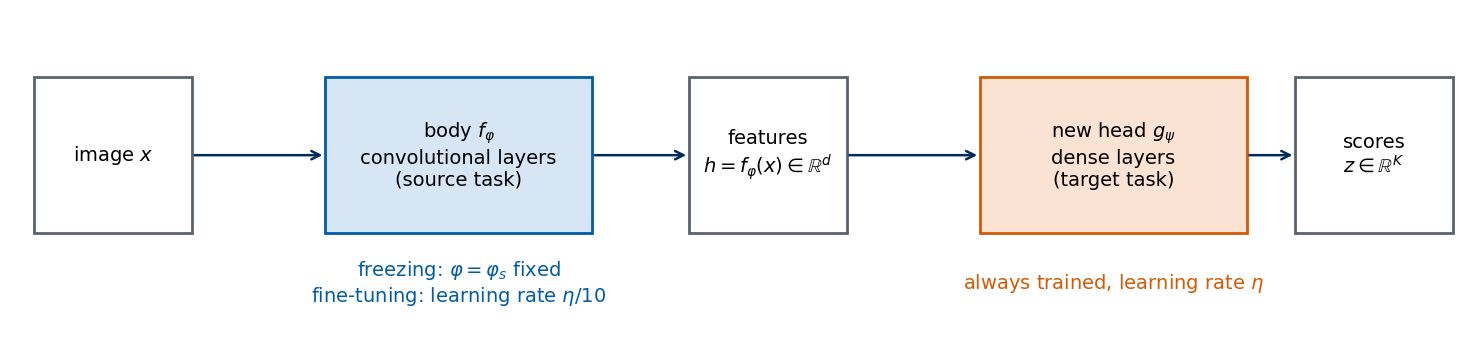

In [2]:
fig, ax = plt.subplots(figsize=(15, 3.8)); ax.set_xlim(0, 12); ax.set_ylim(0, 3); ax.axis("off")
boxes = [(0.2, "image $x$", "white", UJGray), (2.6, "body $f_\\varphi$\nconvolutional layers\n(source task)", "#D6E6F5", UJBlue),
         (5.6, "features\n$h=f_\\varphi(x)\\in\\mathbb{R}^d$", "white", UJGray),
         (8.0, "new head $g_\\psi$\ndense layers\n(target task)", "#FBE3D3", DSOrange), (10.6, "scores\n$z\\in\\mathbb{R}^K$", "white", UJGray)]
for x0, txt, fc, ec in boxes:
    w = 2.2 if "body" in txt or "head" in txt else 1.3
    ax.add_patch(plt.Rectangle((x0, 1.0), w, 1.4, fc=fc, ec=ec, lw=2))
    ax.text(x0 + w / 2, 1.7, txt, ha="center", va="center", fontsize=14)
for x0, x1 in [(1.5, 2.6), (4.8, 5.6), (6.9, 8.0), (10.2, 10.6)]:
    ax.annotate("", xy=(x1, 1.7), xytext=(x0, 1.7), arrowprops=dict(arrowstyle="->", lw=1.8, color=UJNavy))
ax.text(3.7, 0.55, "freezing: $\\varphi=\\varphi_s$ fixed\nfine-tuning: learning rate $\\eta/10$", ha="center", va="center", fontsize=14, color=UJBlue)
ax.text(9.1, 0.55, "always trained, learning rate $\\eta$", ha="center", va="center", fontsize=14, color=DSOrange)
plt.tight_layout(); plt.show()

Transfer learning helps when three conditions meet: the labelled target set is small compared with the number of parameters of the body, the source images share low-level statistics with the target images (edges, textures, colour contrasts), and the target task is hard enough that a small network trained from random initialisation on the few labels does not already solve it. When one of them fails, transfer can bring nothing. Section 10 of Lab 013 gave such a case. The body of the regularised CIFAR-10 CNN, frozen, with a new head trained on MNIST digits, reached 87.0%, 95.8% and 96.2% test accuracy with 10, 100 and 1000 digits per class, while the same network trained from random initialisation reached 89.3%, 96.5% and 97.2% (Lab 013a, PyTorch); the JAX version, Lab 013b, gave 86.8%, 95.2%, 96.3% against 88.1%, 95.3%, 96.7%. MNIST is easy enough that 100 digits per class suffice for a small CNN, and white strokes on black share little with the colour photographs of CIFAR-10.

Blood cells are a harder target: eight classes that differ in the shape and texture of the nucleus and in the colour of granules in the cytoplasm, with labels that require an expert. Section 2 reuses the CIFAR-10 network of Lab 013 on them; Section 3 does the same with a large network pretrained on ImageNet.

### CIFAR-10 and MNIST

Both data sets of that counterexample return in this lab: CIFAR-10 as the source of our own pretrained network, MNIST only as the target on which transfer failed.

CIFAR-10 (A. Krizhevsky, *Learning Multiple Layers of Features from Tiny Images*, technical report, University of Toronto, 2009, [data and report](https://www.cs.toronto.edu/~kriz/cifar.html)) consists of 60 000 colour photographs of $32\times32$ pixels with three channels (red, green, blue, each an integer from 0 to 255), 50 000 for training and 10 000 for testing, 6000 per class. The ten classes are everyday objects and animals: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck. The page states no licence; the authors ask users to cite the report.

MNIST (Y. LeCun, L. Bottou, Y. Bengio, P. Haffner, *Gradient-based learning applied to document recognition*, Proceedings of the IEEE 86, 2278 (1998), [doi:10.1109/5.726791](https://doi.org/10.1109/5.726791)) consists of 70 000 greyscale images of handwritten digits $0,\dots,9$, $28\times28$ pixels with one channel (0 = black background, 255 = white stroke), 60 000 for training and 10 000 for testing.

Both are read from the local caches used in Lab 013 or downloaded from the original sources.

In [3]:
CIFAR_URL = "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz"

def cifar_dir():
    # local copy of the CIFAR-10 batches, downloaded from the authors' page if missing (163 MB)
    d = os.path.join(DATA, "cifar-10-batches-py")
    if os.path.exists(os.path.join(d, "test_batch")): return d
    tgz = os.path.join(DATA, "cifar-10-python.tar.gz")
    print("downloading CIFAR-10 (163 MB) ...")
    urllib.request.urlretrieve(CIFAR_URL, tgz)
    with tarfile.open(tgz) as t: t.extractall(DATA, filter="data")
    return os.path.join(DATA, "cifar-10-batches-py")

def load_batch(d, name):
    with open(os.path.join(d, name), "rb") as f:
        b = pickle.load(f, encoding="bytes")
    return b[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1), np.array(b[b"labels"], dtype=np.int64)  # (N, 32, 32, 3)

D_CIFAR = cifar_dir()
Xc_tr_raw = np.concatenate([load_batch(D_CIFAR, f"data_batch_{i}")[0] for i in range(1, 6)])
yc_tr = np.concatenate([load_batch(D_CIFAR, f"data_batch_{i}")[1] for i in range(1, 6)])
Xc_te_raw, yc_te = load_batch(D_CIFAR, "test_batch")
with open(os.path.join(D_CIFAR, "batches.meta"), "rb") as f:
    CIFAR_CLASSES = [c.decode() for c in pickle.load(f, encoding="bytes")[b"label_names"]]
CIFAR_MEAN = (Xc_tr_raw / 255.0).mean(axis=(0, 1, 2)).astype(np.float32)   # (3,) as in Lab 013a
CIFAR_STD = (Xc_tr_raw / 255.0).std(axis=(0, 1, 2)).astype(np.float32)     # (3,)
MEAN_T, STD_T = torch.tensor(CIFAR_MEAN)[None, :, None, None], torch.tensor(CIFAR_STD)[None, :, None, None]

def cifar_tensor(X_raw):
    # uint8 (N, 32, 32, 3) -> standardised float32 tensor (N, 3, 32, 32)
    return (torch.from_numpy(X_raw).permute(0, 3, 1, 2).float() / 255 - MEAN_T) / STD_T

Xc_te = cifar_tensor(Xc_te_raw)
print("CIFAR-10 training:", Xc_tr_raw.shape, Xc_tr_raw.dtype, "| test:", Xc_te_raw.shape, "| classes:", CIFAR_CLASSES)
print("CIFAR-10 test:", tuple(Xc_te.shape), "| channel means", CIFAR_MEAN.round(3), "| standard deviations", CIFAR_STD.round(3))

CIFAR-10 training: (50000, 32, 32, 3) uint8 | test: (10000, 32, 32, 3) | classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
CIFAR-10 test: (10000, 3, 32, 32) | channel means [0.491 0.482 0.447] | standard deviations [0.247 0.243 0.262]


In [4]:
MNIST_RAW = os.path.join(DATA, "MNIST_raw")
MNIST_MIRRORS = ["https://ossci-datasets.s3.amazonaws.com/mnist/", "https://storage.googleapis.com/cvdf-datasets/mnist/"]

def mnist_idx(name):
    # one MNIST file in the IDX format: images -> (n, 28, 28) uint8, labels -> (n,) uint8
    p = os.path.join(MNIST_RAW, name)
    if os.path.exists(p): raw = open(p, "rb").read()
    elif os.path.exists(p + ".gz"): raw = gzip.open(p + ".gz").read()
    else:
        os.makedirs(MNIST_RAW, exist_ok=True)
        for m in MNIST_MIRRORS:
            try:
                urllib.request.urlretrieve(m + name + ".gz", os.path.join(MNIST_RAW, name + ".gz")); break
            except Exception: pass
        raw = gzip.open(os.path.join(MNIST_RAW, name + ".gz")).read()
    if raw[3] == 3:
        n, r, c = np.frombuffer(raw[4:16], ">i4")
        return np.frombuffer(raw[16:], np.uint8).reshape(n, r, c)
    return np.frombuffer(raw[8:], np.uint8)

Xm_te, ym_te = mnist_idx("t10k-images-idx3-ubyte"), mnist_idx("t10k-labels-idx1-ubyte")     # test images suffice for the figure
assert Xm_te.shape == (10000, 28, 28)
print("MNIST test images:", Xm_te.shape, Xm_te.dtype, "| digits per class:", np.bincount(ym_te))

MNIST test images: (10000, 28, 28) uint8 | digits per class: [ 980 1135 1032 1010  982  892  958 1028  974 1009]


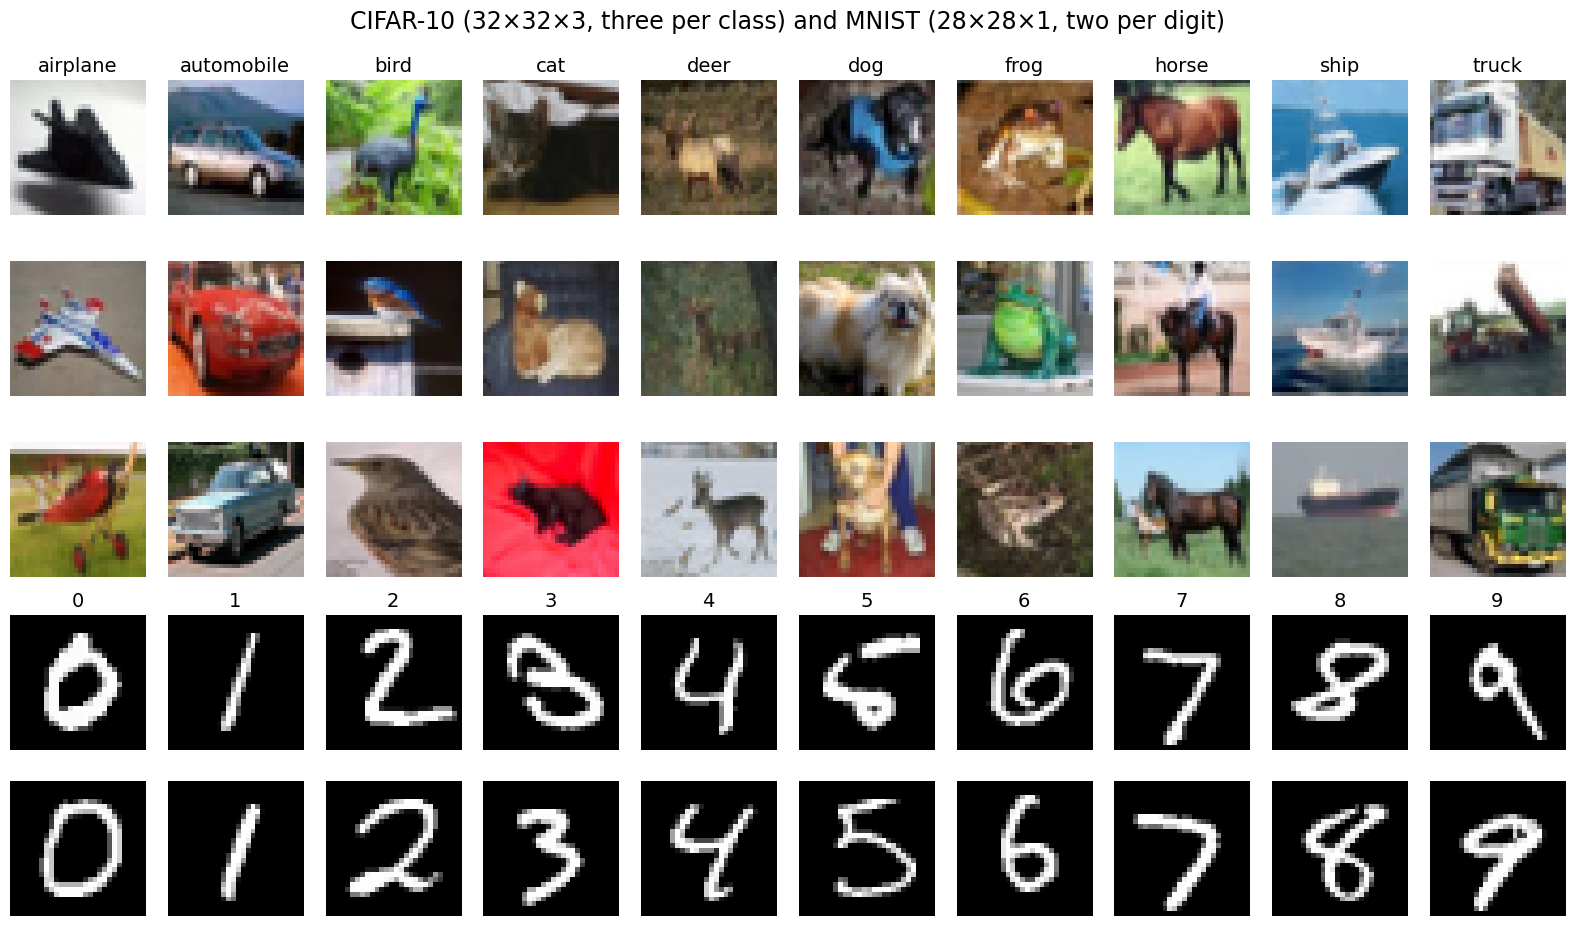

In [5]:
fig, axes = plt.subplots(5, 10, figsize=(16, 9.5), gridspec_kw={"height_ratios": [1, 1, 1, 0.9, 0.9]})
for c in range(10):
    for r in range(3):
        axes[r, c].imshow(Xc_tr_raw[np.flatnonzero(yc_tr == c)[r]])
    axes[0, c].set_title(CIFAR_CLASSES[c], fontsize=14)
    for r in range(2):
        axes[3 + r, c].imshow(Xm_te[np.flatnonzero(ym_te == c)[r]], cmap="gray")
    axes[3, c].set_title(str(c), fontsize=14)
for a in axes.ravel(): a.axis("off")
fig.suptitle("CIFAR-10 (32×32×3, three per class) and MNIST (28×28×1, two per digit)"); plt.tight_layout(); plt.show()

## 2. A CIFAR-10 network on blood cells

The first source network is our own: the regularised CNN that Lab 013 trained on CIFAR-10 photographs. We put its convolutional body in front of new layers for the eight cell types and compare three ways of training with 10, 100 and 800 labelled cells per type.

### Blood cell images

The images come from A. Acevedo, A. Merino, S. Alférez, Á. Molina, L. Boldú, J. Rodellar, *A dataset of microscopic peripheral blood cell images for development of automatic recognition systems*, Data in Brief 30, 105474 (2020), [doi:10.1016/j.dib.2020.105474](https://doi.org/10.1016/j.dib.2020.105474): 17 092 images of individual normal cells in peripheral blood smears, recorded with a CellaVision DM96 analyser at the Hospital Clínic of Barcelona from donors without infection, haematological or oncological disease and without pharmacological treatment, and labelled by clinical pathologists. The originals have $360\times363$ pixels. BloodMNIST is the version of the MedMNIST collection (J. Yang et al., *MedMNIST v2: A large-scale lightweight benchmark for 2D and 3D biomedical image classification*, Scientific Data 10, 41 (2023), [doi:10.1038/s41597-022-01721-8](https://doi.org/10.1038/s41597-022-01721-8)), resized to $28\times28$ and $64\times64$ pixels with three channels (red, green, blue, integers 0–255) and split into 11 959 training, 1712 validation and 3421 test images; it is distributed on [Zenodo](https://zenodo.org/records/10519652) under the Creative Commons Attribution 4.0 licence. We draw the labelled examples from the training images and report every accuracy on the full test set; the validation images are not used.

The eight classes, with their integer labels:

| $c$ | cell type | what it is |
|---|---|---|
| 0 | basophil | granulocyte with large dark-violet granules that often hide the nucleus; the rarest white blood cell |
| 1 | eosinophil | granulocyte with large orange-red granules and a nucleus of usually two lobes; active against parasites and in allergy |
| 2 | erythroblast | nucleated precursor of the red blood cell, normally found in the bone marrow |
| 3 | immature granulocyte | precursors of the granulocytes: promyelocytes, myelocytes and metamyelocytes, grouped into one class |
| 4 | lymphocyte | small cell whose round, dense nucleus fills most of it, with a thin rim of blue cytoplasm; adaptive immunity |
| 5 | monocyte | the largest white blood cell, with a folded or kidney-shaped nucleus and grey-blue cytoplasm; precursor of macrophages |
| 6 | neutrophil | the most frequent white blood cell, with a nucleus of two to five lobes and pale, finely granular cytoplasm; first defence against bacteria |
| 7 | platelet | small fragment of a megakaryocyte without nucleus, involved in blood clotting |

Each `.npz` file holds `train_images` of shape $(N,H,W,3)$ with `uint8` values, `train_labels` of shape $(N,1)$, and the same arrays for `val` and `test`. The two resolutions contain the same cells in the same order. Section 2 uses the $28\times28$ version, Section 3 the $64\times64$ version.

In [6]:
BLOOD_URL = "https://zenodo.org/records/10519652/files/{}?download=1"
BLOOD_TYPES = ["basophil", "eosinophil", "erythroblast", "immature granulocyte",
               "lymphocyte", "monocyte", "neutrophil", "platelet"]

def load_blood(name):
    # read a MedMNIST .npz file from data/, download it from Zenodo if it is not there
    path = os.path.join(DATA, name)
    if not os.path.exists(path):
        print("downloading", name, "...")
        urllib.request.urlretrieve(BLOOD_URL.format(name), path)
    with np.load(path) as d:
        return {k: d[k] for k in d.files}

b28 = load_blood("bloodmnist.npz")
Xb_tr_raw, yb_tr = b28["train_images"], b28["train_labels"].ravel().astype(np.int64)   # (11959, 28, 28, 3) uint8
Xb_te_raw, yb_te = b28["test_images"], b28["test_labels"].ravel().astype(np.int64)     # (3421, 28, 28, 3)
b64 = load_blood("bloodmnist_64.npz")                                                   # the same cells at 64 x 64 pixels
assert Xb_tr_raw.shape == (11959, 28, 28, 3) and Xb_te_raw.shape == (3421, 28, 28, 3)
assert np.array_equal(b64["train_labels"].ravel(), yb_tr) and np.array_equal(b64["test_labels"].ravel(), yb_te)
BLOOD_GRID_PATH = os.path.join(FIGS, "transfer_blood_examples.png")                      # example grid for the slides
print(f"{'cell type':22s} {'training':>8s} {'test':>6s}")
for c, name in enumerate(BLOOD_TYPES):
    print(f"{name:22s} {np.sum(yb_tr == c):8d} {np.sum(yb_te == c):6d}")

cell type              training   test
basophil                    852    244
eosinophil                 2181    624
erythroblast               1085    311
immature granulocyte       2026    579
lymphocyte                  849    243
monocyte                    993    284
neutrophil                 2330    666
platelet                   1643    470


saved figures/transfer_blood_examples.png


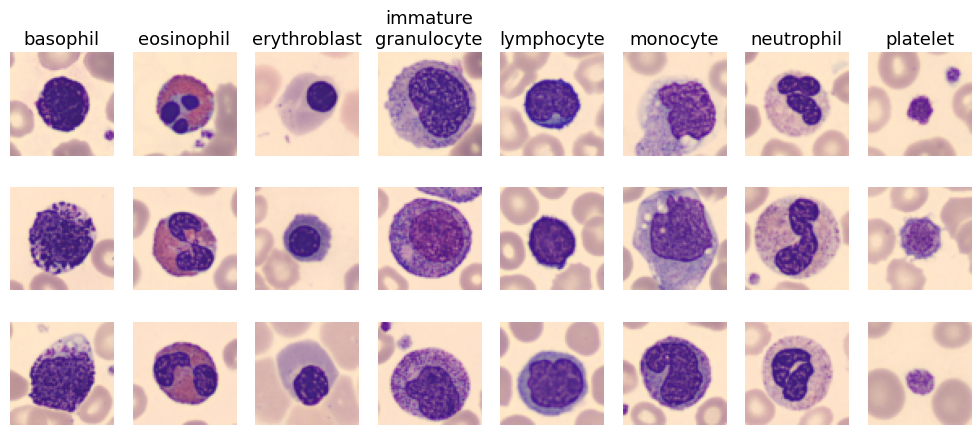

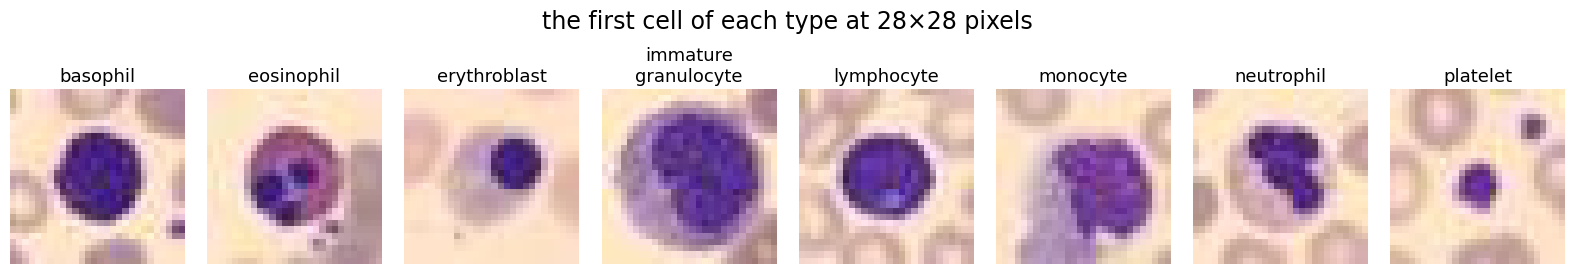

In [7]:
def blood_grid(path=None):
    # three training images per cell type at 64 x 64 pixels, large labels (also used on a slide)
    with plt.rc_context({"font.size": 13}):
        fig, axes = plt.subplots(3, 8, figsize=(10, 4.8))
        for c in range(8):
            for r in range(3):
                i = np.flatnonzero(yb_tr == c)[r]
                axes[r, c].imshow(b64["train_images"][i]); axes[r, c].axis("off")
            axes[0, c].set_title(BLOOD_TYPES[c].replace(" ", "\n"), fontsize=13)
        fig.tight_layout()
        if path: fig.savefig(path, dpi=150); print("saved", path)
        plt.show()

blood_grid(BLOOD_GRID_PATH)
fig, axes = plt.subplots(1, 8, figsize=(16, 3.0))
for c in range(8):
    axes[c].imshow(Xb_tr_raw[np.flatnonzero(yb_tr == c)[0]]); axes[c].axis("off"); axes[c].set_title(BLOOD_TYPES[c].replace(" ", "\n"), fontsize=13)
fig.suptitle("the first cell of each type at 28×28 pixels"); plt.tight_layout(); plt.show()

The classes are unbalanced: neutrophils are the most frequent type, lymphocytes the rarest with 849 training images. A balanced subset with 1000 cells per type therefore does not exist, and the largest budget we use is 800 cells per type (6400 images); the others are 10 and 100 per type. For each type we fix one random order of its training images (seed 0) and take the first 10, 100 or 800; the subsets are therefore nested, every cell of the 10-per-type subset is also in the larger ones. `SUB[n]` holds the indices of the selected images in the training set, `POS[n]` their positions inside the largest subset, so that arrays prepared once for the largest subset serve all budgets.

In [8]:
BUDGETS = [10, 100, 800]                       # labelled cells per type

def nested_subsets(y, budgets, seed=0):
    # one random order of the images of each class; the first n of every class form the subset of size n
    r = np.random.default_rng(seed)
    perms = [r.permutation(np.flatnonzero(y == c)) for c in range(len(BLOOD_TYPES))]
    return {n: np.concatenate([p[:n] for p in perms]) for n in budgets}

SUB = nested_subsets(yb_tr, BUDGETS)                                # indices into the training set
POS = {n: np.array([np.flatnonzero(SUB[BUDGETS[-1]] == i)[0] for i in SUB[n]]) for n in BUDGETS}  # positions inside the largest subset
assert min(np.bincount(yb_tr)) >= max(BUDGETS)
assert set(SUB[10]) <= set(SUB[100]) <= set(SUB[800])
assert all(np.array_equal(SUB[BUDGETS[-1]][POS[n]], SUB[n]) for n in BUDGETS)
for n in BUDGETS: print(f"{n:4d} per type: {len(SUB[n]):5d} images, counts per type {np.bincount(yb_tr[SUB[n]])}")

  10 per type:    80 images, counts per type [10 10 10 10 10 10 10 10]
 100 per type:   800 images, counts per type [100 100 100 100 100 100 100 100]
 800 per type:  6400 images, counts per type [800 800 800 800 800 800 800 800]


### The CIFAR-10 network of Lab 013

Lab 013a saved the weights of its regularised CNN. Loading them needs the same class definition. The body consists of three convolutional blocks (convolution $3\times3$, batch normalisation, ReLU (rectified linear unit), max pooling $2\times2$, and dropout in the second and third block); it maps an image of shape $(N,3,32,32)$ to feature maps of shape $(N,128,4,4)$. The head flattens them to 2048 numbers and applies a dense layer with 512 units, ReLU and a dense layer with 10 outputs. The network was trained for 12 epochs on 10 000 CIFAR-10 images with augmentation and weight decay. The CIFAR-10 test set of Section 1 checks that the loaded weights reproduce the accuracy of Lab 013a.

In [9]:
class CifarCNN(nn.Module):
    # the CIFAR-10 CNN of Lab 013a; regularise=True: batch normalisation and dropout
    def __init__(self, regularise=False):
        super().__init__()
        bn = (lambda c: nn.BatchNorm2d(c)) if regularise else (lambda c: nn.Identity())
        drop = (lambda p: nn.Dropout(p)) if regularise else (lambda p: nn.Identity())
        self.body = nn.Sequential(OrderedDict(
            conv1=nn.Conv2d(3, 32, 3, padding=1), bn1=bn(32), act1=nn.ReLU(), pool1=nn.MaxPool2d(2),
            conv2=nn.Conv2d(32, 64, 3, padding=1), bn2=bn(64), act2=nn.ReLU(), pool2=nn.MaxPool2d(2), drop2=drop(0.2),
            conv3=nn.Conv2d(64, 128, 3, padding=1), bn3=bn(128), act3=nn.ReLU(), pool3=nn.MaxPool2d(2), drop3=drop(0.3)))
        self.head = nn.Sequential(OrderedDict(
            flatten=nn.Flatten(), drop4=drop(0.4), fc1=nn.Linear(2048, 512), act4=nn.ReLU(), fc2=nn.Linear(512, 10)))
    def forward(self, x):                       # (N, 3, 32, 32) -> body (N, 128, 4, 4) -> head (N, 10)
        return self.head(self.body(x))

def count_params(module):
    return sum(p.numel() for p in module.parameters())

@torch.no_grad()
def predict(model, X, batch=500):
    # logits in evaluation mode, in batches
    model.eval()
    return torch.cat([model(X[k:k + batch]) for k in range(0, len(X), batch)])

def accuracy(model, X, y):
    return (predict(model, X).argmax(1) == torch.as_tensor(y)).float().mean().item()

def train_steps(model, params, lr, X, y, steps, eval_modules=(), batch=64, seed=0):
    # Adam on the cross-entropy for `steps` mini-batches drawn at random from (X, y); only `params` are updated;
    # modules in eval_modules stay in evaluation mode. Returns (seconds, mean training loss of the last 50 steps).
    opt = torch.optim.Adam(params, lr=lr)
    g = torch.Generator().manual_seed(seed)
    y = torch.as_tensor(y)
    losses, t0 = [], time.time()
    for t in range(steps):
        model.train()
        for m in eval_modules: m.eval()
        idx = torch.randint(0, len(X), (batch,), generator=g)
        loss = F.cross_entropy(model(X[idx]), y[idx])
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    return time.time() - t0, float(np.mean(losses[-50:]))

def n_steps(n_per_type, epochs, minimum, batch=64):
    # number of mini-batch steps: `epochs` passes over the 8 * n_per_type images, but at least `minimum`
    return max(minimum, int(np.ceil(epochs * 8 * n_per_type / batch)))

cifar_cnn = CifarCNN(regularise=True)
W_PATH = os.path.join(RESULTS, "Lab_013a_regularised_cnn.pt")
if os.path.exists(W_PATH):
    cifar_cnn.load_state_dict(torch.load(W_PATH))
    print("loaded", W_PATH)
else:
    # fallback (e.g. in Colab): a short retraining on 10 000 CIFAR-10 images, about 3 epochs
    print("weights of Lab 013a not found: retraining the regularised CNN briefly")
    torch.manual_seed(0)
    train_steps(cifar_cnn, cifar_cnn.parameters(), 1e-3, cifar_tensor(Xc_tr_raw[:10000]), yc_tr[:10000], steps=240, batch=128)
acc_cifar = accuracy(cifar_cnn, Xc_te, yc_te)
print(f"parameters: body {count_params(cifar_cnn.body)}, head {count_params(cifar_cnn.head)}")
print(f"CIFAR-10 test accuracy of the loaded network: {100 * acc_cifar:.1f}%  (Lab 013a: 66.5%)")
assert acc_cifar > 0.5

loaded results/Lab_013a_regularised_cnn.pt


parameters: body 93696, head 1054218
CIFAR-10 test accuracy of the loaded network: 66.5%  (Lab 013a: 66.5%)


Two tools make the surgery visible. `draw_blocks` draws a network as a chain of boxes, one per block, with its output shape, its number of parameters and its status: trained on the source task, frozen (grey, hatched), removed (red, crossed out), new and trained (orange), or unfrozen for fine-tuning (green). `param_table` lists, for every layer with parameters, how many it holds and whether the optimiser will change them. A convolutional block of the CIFAR-10 network is convolution, batch normalisation, ReLU and max pooling (with dropout in blocks 2 and 3). Almost all of its parameters sit in the head, 1 049 088 of 1 147 914 in the first dense layer alone; the body, the part that is transferred, is small.

In [10]:
from matplotlib.patches import FancyBboxPatch

def short_count(p):
    # 1049088 -> "1.05 M par.", 18624 -> "18.6 k par.", 960 -> "960 par."
    return f"{p / 1e6:.2f} M par." if p >= 1e6 else (f"{p / 1e3:.1f} k par." if p >= 1e4 else f"{p} par.")

# status of a block -> (fill colour, edge colour, hatch, label under the box)
BLOCK_STYLE = {"data": ("white", UJGray, None, ""),
               "source": ("#D6E6F5", UJBlue, None, "source"),
               "frozen": ("#D9D9D9", "#6E6E6E", "///", "frozen"),
               "new": ("#FBE3D3", DSOrange, None, "new, trained"),
               "removed": ("white", "#C0392B", None, "removed"),
               "unfrozen": ("#D3EDDC", Green, None, "fine-tuned")}

def draw_blocks(blocks, title, path=None, w=2.3, h=2.1, gap=0.45, fontsize=11.5):
    """Draw a network as a row of boxes joined by arrows.

    blocks : list of dicts with keys
        name   : first line in the box, e.g. "conv block 1";
        detail : further lines (shapes, channels), may be "";
        params : number of parameters (int) or None;
        status : one of BLOCK_STYLE ("data", "source", "frozen", "new", "removed", "unfrozen");
        tag    : optional text under the box replacing the default label of the status;
        row    : 0 (default) for the main row, 1 for a box drawn above the main row (e.g. a removed head);
        at     : for row 1, the index of the main-row box above which it is drawn.
    title : title of the figure; path : PNG file to save (None: only show);
    w, h, gap : box width, box height and horizontal gap (data units); fontsize : text size in the boxes.
    """
    main = [b for b in blocks if b.get("row", 0) == 0]
    upper = [b for b in blocks if b.get("row", 0) == 1]
    width = len(main) * w + (len(main) - 1) * gap
    y_up = h + 0.95                                            # bottom of the upper row
    top = (y_up + h + 0.15) if upper else (h + 0.15)
    scale = 0.5                                                # inches per data unit
    fig, ax = plt.subplots(figsize=(width * scale + 0.3, (top + 0.95) * scale + 0.55))

    def box(x, y, b):
        fc, ec, hatch, tag = BLOCK_STYLE[b["status"]]
        removed = b["status"] == "removed"
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.0,rounding_size=0.12", fc=fc, ec=ec,
                                    lw=2.2, hatch=hatch, ls="--" if removed else "-", zorder=2))
        lines = [b["name"]] + ([b["detail"]] if b.get("detail") else []) + ([short_count(b["params"])] if b.get("params") else [])
        ax.text(x + w / 2, y + h / 2, "\n".join(lines), ha="center", va="center", fontsize=fontsize, zorder=4,
                color="#C0392B" if removed else "black",
                bbox=dict(fc="white", ec="none", alpha=1.0, pad=0.5) if b["status"] == "frozen" else None)
        if removed:                                            # cross out a removed block
            ax.plot([x + 0.1, x + w - 0.1], [y + 0.1, y + h - 0.1], color="#C0392B", lw=1.4, alpha=0.6, zorder=3)
            ax.plot([x + 0.1, x + w - 0.1], [y + h - 0.1, y + 0.1], color="#C0392B", lw=1.4, alpha=0.6, zorder=3)
        tag = b.get("tag", tag)
        if tag:
            ax.text(x + w / 2, y - 0.1, tag, ha="center", va="top", fontsize=fontsize - 0.5, color=ec, style="italic")

    for i, b in enumerate(main):
        box(i * (w + gap), 0, b)
        if i > 0:
            ax.annotate("", xy=(i * (w + gap), h / 2), xytext=(i * (w + gap) - gap, h / 2),
                        arrowprops=dict(arrowstyle="->", lw=1.6, color=UJNavy))
    for b in upper:
        box(b["at"] * (w + gap), y_up, b)
    ax.set_xlim(-0.1, width + 0.1); ax.set_ylim(-0.85, top); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=fontsize + 3)
    fig.tight_layout()
    if path: fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white"); print("saved", path)
    plt.show()
    return sum(b.get("params") or 0 for b in blocks if b["status"] != "removed")   # parameters of the drawn network

def param_table(model, title, depth=None):
    # one row per module that holds parameters directly (or per child up to `depth` levels): count and trainability
    rows = []
    for name, mod in model.named_modules():
        if name == "" or (depth is not None and name.count(".") >= depth): continue
        if depth is None and any(True for _ in mod.children()): continue           # leaves only
        ps = list(mod.parameters())
        if not ps: continue
        n_tr = sum(p.numel() for p in ps if p.requires_grad); n_all = sum(p.numel() for p in ps)
        rows.append((name, n_all, "trained" if n_tr == n_all else ("frozen" if n_tr == 0 else "partly")))
    print(f"{title}\n{'layer':22s} {'parameters':>11s}  status")
    for name, k, st in rows: print(f"{name:22s} {k:11,d}  {st}")
    n_tr = sum(p.numel() for p in model.parameters() if p.requires_grad); n_all = count_params(model)
    print(f"{'trainable':22s} {n_tr:11,d}\n{'frozen':22s} {n_all - n_tr:11,d}\n")

def fmt_shape(shape):
    # (C, H, W) -> "H×W×C", (n,) -> "n"
    return f"{shape[1]}×{shape[2]}×{shape[0]}" if len(shape) == 3 else "×".join(str(k) for k in shape)

@torch.no_grad()
def hook_shapes(model, x, names):
    # output shape (without the batch axis) of the named submodules for the input x, recorded by forward hooks
    out, handles = {}, []
    for n in names:
        handles.append(model.get_submodule(n).register_forward_hook(lambda m, i, o, n=n: out.__setitem__(n, fmt_shape(tuple(o.shape[1:])))))
    try:
        model.eval(); model(x)
    finally:
        for h in handles: h.remove()
    return out

def stage_table(model, stages, title):
    # stages: list of (stage name, output shape, [module paths]); one row per stage, totals at the end
    print(f"{title}\n{'stage':14s} {'output shape':>13s} {'parameters':>11s}  trainable")
    for name, shape, mods in stages:
        ps = [p for m in mods for p in model.get_submodule(m).parameters()]
        n_all, n_tr = sum(p.numel() for p in ps), sum(p.numel() for p in ps if p.requires_grad)
        print(f"{name:14s} {shape:>13s} {n_all:11,d}  {'yes' if n_tr == n_all else ('no' if n_tr == 0 else 'partly')}")
    n_tr = sum(p.numel() for p in model.parameters() if p.requires_grad); n_all = count_params(model)
    assert sum(sum(p.numel() for m in mods for p in model.get_submodule(m).parameters()) for _, _, mods in stages) == n_all
    print(f"{'total':14s} {'':>13s} {n_all:11,d}\n{'trainable':14s} {'':>13s} {n_tr:11,d}\n{'frozen':14s} {'':>13s} {n_all - n_tr:11,d}\n")

saved results/Lab_014a_arch_cifar_source.png


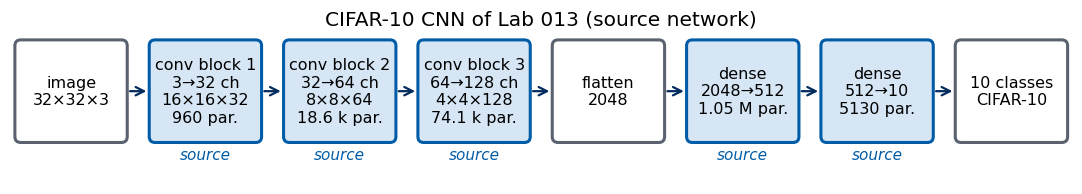

In [11]:
def cifar_body_blocks(model, x, status, tag=None):
    # one box per convolutional block, with channels, output shape and parameters read from the model
    b = model.body
    sh = hook_shapes(model, x, [f"body.pool{i}" for i in (1, 2, 3)])
    return [dict(name=f"conv block {i}", detail=f"{getattr(b, f'conv{i}').in_channels}→{getattr(b, f'conv{i}').out_channels} ch\n{sh[f'body.pool{i}']}",
                 params=count_params(getattr(b, f"conv{i}")) + count_params(getattr(b, f"bn{i}")), status=status, **({"tag": tag} if tag else {}))
            for i in (1, 2, 3)]

def dense_box(layer, status, tag=None, **kw):
    return dict(name="dense", detail=f"{layer.in_features}→{layer.out_features}", params=count_params(layer), status=status,
                **({"tag": tag} if tag else {}), **kw)

X32 = torch.zeros(1, 3, 32, 32)
hd = cifar_cnn.head
TOTAL_CIFAR = draw_blocks([dict(name="image", detail="32×32×3", status="data")] + cifar_body_blocks(cifar_cnn, X32, "source")
                          + [dict(name="flatten", detail=hook_shapes(cifar_cnn, X32, ["head.flatten"])["head.flatten"], status="data"),
                             dense_box(hd.fc1, "source"), dense_box(hd.fc2, "source"),
                             dict(name=f"{hd.fc2.out_features} classes", detail="CIFAR-10", status="data")],
                          "CIFAR-10 CNN of Lab 013 (source network)", os.path.join(RESULTS, "Lab_014a_arch_cifar_source.png"))
assert TOTAL_CIFAR == count_params(cifar_cnn)

`torchinfo.summary` prints the same information layer by layer, with the output shape of every layer for one input image.

In [12]:
try:
    from torchinfo import summary
    info = summary(cifar_cnn, input_size=(1, 3, 32, 32), col_names=("output_size", "num_params"), depth=2, verbose=0)
    print(info)
    assert info.total_params == TOTAL_CIFAR, "diagram and torchinfo disagree"
    print(f"diagram total {TOTAL_CIFAR:,} parameters = torchinfo total {info.total_params:,}")
except ImportError:
    print("torchinfo is not installed: pip install torchinfo")

Layer (type:depth-idx)                   Output Shape              Param #
CifarCNN                                 [1, 10]                   --
├─Sequential: 1-1                        [1, 128, 4, 4]            --
│    └─Conv2d: 2-1                       [1, 32, 32, 32]           896
│    └─BatchNorm2d: 2-2                  [1, 32, 32, 32]           64
│    └─ReLU: 2-3                         [1, 32, 32, 32]           --
│    └─MaxPool2d: 2-4                    [1, 32, 16, 16]           --
│    └─Conv2d: 2-5                       [1, 64, 16, 16]           18,496
│    └─BatchNorm2d: 2-6                  [1, 64, 16, 16]           128
│    └─ReLU: 2-7                         [1, 64, 16, 16]           --
│    └─MaxPool2d: 2-8                    [1, 64, 8, 8]             --
│    └─Dropout: 2-9                      [1, 64, 8, 8]             --
│    └─Conv2d: 2-10                      [1, 128, 8, 8]            73,856
│    └─BatchNorm2d: 2-11                 [1, 128, 8, 8]            256
│   

### Adapting the input

A frozen body can only be used on inputs that look, numerically, like the inputs it was trained on: three colour channels, $32\times32$ pixels, and each channel standardised with the CIFAR-10 mean $\mu_c$ and standard deviation $\sigma_c$ of that channel,
$$x_c\;\leftarrow\;\frac{x_c/255-\mu_c}{\sigma_c},\qquad c\in\{\text{red},\text{green},\text{blue}\}, \tag{4}$$
where $x_c$ is the integer value of channel $c$ of a pixel. BloodMNIST images already have three channels. We enlarge them from 28 to 32 pixels by bilinear interpolation, so that after three poolings the feature maps have the size $4\times4$ that the new layers expect, and we standardise them with the CIFAR-10 statistics, not with those of BloodMNIST: the first-layer kernels and the running averages of batch normalisation were fitted to inputs on that scale. Shapes: `uint8` $(N,28,28,3)$ → `float32` $(N,3,32,32)$. We prepare the largest labelled subset (6400 images) and the 3421 test images once.

In [13]:
def blood_as_cifar(X_raw):
    # uint8 (N, 28, 28, 3) -> float32 (N, 3, 32, 32), enlarged by bilinear interpolation, CIFAR-10 standardisation
    X = torch.from_numpy(X_raw).permute(0, 3, 1, 2).float() / 255                   # (N, 3, 28, 28) in [0, 1]
    X = F.interpolate(X, size=(32, 32), mode="bilinear", align_corners=False)       # (N, 3, 32, 32)
    return (X - MEAN_T) / STD_T

Xa_sub, ya_sub = blood_as_cifar(Xb_tr_raw[SUB[800]]), torch.from_numpy(yb_tr[SUB[800]])   # largest labelled subset
Xa_te, ya_te = blood_as_cifar(Xb_te_raw), torch.from_numpy(yb_te)                        # full test set
assert Xa_sub.shape == (6400, 3, 32, 32) and Xa_te.shape == (3421, 3, 32, 32)
print("adapted blood cells:", tuple(Xa_sub.shape), " test:", tuple(Xa_te.shape))
print("channel means after CIFAR-10 standardisation:", Xa_te.mean((0, 2, 3)).numpy().round(2),
      " standard deviations:", Xa_te.std((0, 2, 3)).numpy().round(2))
print("CIFAR-10 test images for comparison:        ", Xc_te.mean((0, 2, 3)).numpy().round(2),
      " standard deviations:", Xc_te.std((0, 2, 3)).numpy().round(2))

adapted blood cells: (6400, 3, 32, 32)  test: (3421, 3, 32, 32)


channel means after CIFAR-10 standardisation: [1.22 0.73 0.95]  standard deviations: [0.85 0.97 0.42]


CIFAR-10 test images for comparison:         [0.01 0.01 0.01]  standard deviations: [1. 1. 1.]


Under the CIFAR-10 standardisation the blood-cell images do not have zero mean and unit variance: the channel means are 1.22, 0.73 and 0.95 and the standard deviation of the blue channel is only 0.42, against 0.01 and 1.0 for CIFAR-10 test images. Blood smears are bright, pink and much less varied in colour than photographs, so the frozen first layer sees inputs shifted far from what it was trained on. This mismatch is part of what the frozen body has to cope with; it disappears once the body is allowed to adapt.

### Freezing the body and adding new layers

Freezing in PyTorch has three parts, and all three are needed. Setting `p.requires_grad = False` for every parameter of the body tells automatic differentiation not to compute gradients for them, which also shortens the backward pass. Passing only the new parameters to the optimiser, `torch.optim.Adam(model.head.parameters())`, guarantees that the optimiser holds no state for the body and never updates it. Finally, the body must stay in evaluation mode, `model.body.eval()` after every `model.train()`: `requires_grad=False` does not stop batch normalisation from replacing its running means and variances by statistics of blood-cell mini-batches, and it does not switch off dropout.

The new layers are a dense layer from 2048 to 128 units, ReLU, dropout with rate 0.3, and a dense layer from 128 units to 8 outputs, with
$$2048\cdot128+128+128\cdot8+8=263\,304 \tag{5}$$
parameters (weights and biases of the two dense layers). To verify that the body stays fixed, its complete `state_dict` (parameters and batch-normalisation buffers) is copied before training and compared entry by entry afterwards, and the sum of the absolute values of all its entries is printed as a checksum.

In [14]:
class TransferNet(nn.Module):
    # a body (N, 3, 32, 32) -> (N, 128, 4, 4) followed by new layers for the 8 cell types
    def __init__(self, body, n_classes=8):
        super().__init__()
        self.body = body
        self.head = nn.Sequential(OrderedDict(flatten=nn.Flatten(), fc1=nn.Linear(2048, 128), act=nn.ReLU(),
                                              drop=nn.Dropout(0.3), fc2=nn.Linear(128, n_classes)))
    def forward(self, x):
        return self.head(self.body(x))

def set_trainable(module, flag):
    for p in module.parameters(): p.requires_grad = flag

def checksum(module):
    # sum of |entries| over parameters and buffers (batch-norm running averages)
    return sum(v.double().abs().sum().item() for v in module.state_dict().values())

def same_state(sd1, sd2):
    return all(torch.equal(sd1[k], sd2[k]) for k in sd1)

torch.manual_seed(0)
demo = TransferNet(copy.deepcopy(cifar_cnn.body)); set_trainable(demo.body, False)
n_train = sum(p.numel() for p in demo.parameters() if p.requires_grad)
print(f"frozen network: {n_train} trainable parameters (new layers) of {count_params(demo)}; body {count_params(demo.body)} frozen")
assert n_train == count_params(demo.head) == 2048 * 128 + 128 + 128 * 8 + 8

frozen network: 263304 trainable parameters (new layers) of 357000; body 93696 frozen


The surgery on the CIFAR-10 network replaces its head. In the diagrams frozen blocks are grey and hatched (excluded from training: `requires_grad=False` in PyTorch, outside the optimiser's filter in JAX), removed blocks are red and crossed out, and new blocks are orange. The body keeps its trained weights and is frozen; the old head (dense 512 and dense 10 for the ten CIFAR-10 classes) is removed; a new head ends in 8 outputs for the eight cell types. The tables list, for every layer with parameters, the number of parameters and whether they are trained, before and after freezing.

before freezing: CIFAR-10 body + new layers
layer                   parameters  status
body.conv1                     896  trained
body.bn1                        64  trained
body.conv2                  18,496  trained
body.bn2                       128  trained
body.conv3                  73,856  trained
body.bn3                       256  trained
head.fc1                   262,272  trained
head.fc2                     1,032  trained
trainable                  357,000
frozen                           0

after freezing the body
layer                   parameters  status
body.conv1                     896  frozen
body.bn1                        64  frozen
body.conv2                  18,496  frozen
body.bn2                       128  frozen
body.conv3                  73,856  frozen
body.bn3                       256  frozen
head.fc1                   262,272  trained
head.fc2                     1,032  trained
trainable                  263,304
frozen                      93,696

per st

saved results/Lab_014a_arch_cifar_frozen.png


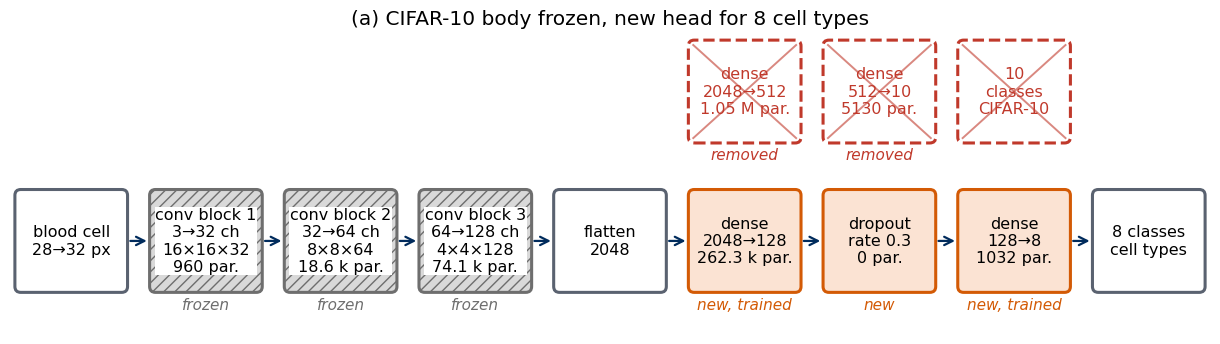

In [15]:
param_table(TransferNet(copy.deepcopy(cifar_cnn.body)), "before freezing: CIFAR-10 body + new layers")
param_table(demo, "after freezing the body")
SHD = hook_shapes(demo, X32, ["body.pool1", "body.pool2", "body.pool3", "head.flatten", "head.fc1", "head.fc2"])
CIFAR_STAGES = [(f"conv block {i}", SHD[f"body.pool{i}"], [f"body.conv{i}", f"body.bn{i}"]) for i in (1, 2, 3)] + \
               [("dense", SHD["head.fc1"], ["head.fc1"]), ("dense", SHD["head.fc2"], ["head.fc2"])]
stage_table(demo, CIFAR_STAGES, "per stage, after freezing (32×32 input)")

def new_head_boxes(model, tag=None):
    hd = model.head
    return [dict(name="flatten", detail=SHD["head.flatten"], status="data"), dense_box(hd.fc1, "new", tag),
            dict(name="dropout", detail=f"rate {hd.drop.p}\n0 par.", status="new", tag="new"),
            dense_box(hd.fc2, "new", tag), dict(name=f"{hd.fc2.out_features} classes", detail="cell types", status="data")]

OLD_HEAD = [dense_box(cifar_cnn.head.fc1, "removed", "removed", row=1, at=5), dense_box(cifar_cnn.head.fc2, "removed", "removed", row=1, at=6),
            dict(name=f"{cifar_cnn.head.fc2.out_features}\nclasses", detail="CIFAR-10", status="removed", row=1, at=7, tag="")]
total = draw_blocks([dict(name="blood cell", detail="28→32 px", status="data")] + cifar_body_blocks(demo, X32, "frozen")
                    + new_head_boxes(demo) + OLD_HEAD, "(a) CIFAR-10 body frozen, new head for 8 cell types",
                    os.path.join(RESULTS, "Lab_014a_arch_cifar_frozen.png"))
assert total == count_params(demo)

`torchview.draw_graph` draws the computational graph of the transferred network directly from a forward pass, with modules shown down to depth 2 for the CIFAR-10 network and depth 1 for ResNet-18.

saved results/Lab_014a_torchview_cifar_frozen.png


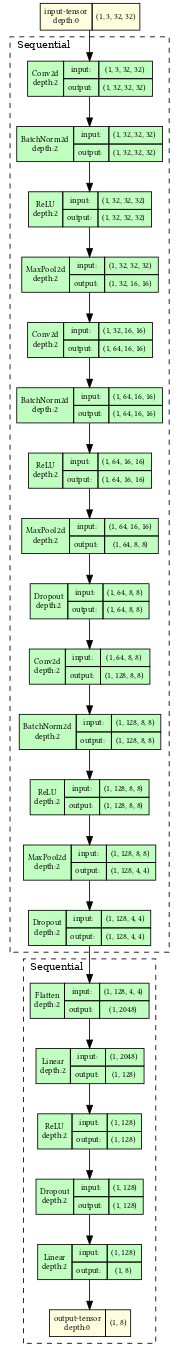

In [16]:
try:
    from torchview import draw_graph
    from IPython.display import Image, display
    g = draw_graph(demo, input_size=(1, 3, 32, 32), depth=2, expand_nested=True, graph_name="transfer_cifar")
    path = g.visual_graph.render(os.path.join(RESULTS, "Lab_014a_torchview_cifar_frozen"), format="png", cleanup=True)
    print("saved", path); display(Image(path, width=420))
except Exception as e:                                   # torchview or graphviz missing
    print("torchview graph not drawn:", e)

### Three training regimes

The three regimes differ only in the starting point of the body and in which parameters move:

* (a) frozen: the CIFAR-10 body, frozen, with the new layers trained by Adam with learning rate $10^{-3}$;
* (b) random initialisation: the same architecture with a randomly initialised body, all parameters trained with learning rate $10^{-3}$ for twice as many steps as (a);
* (c) fine-tuning: model (a) after its training, with the body unfrozen and all parameters trained for as many steps again with learning rate $10^{-4}$, ten times smaller. Regimes (b) and (c) thus get the same total number of steps.

Every mini-batch has 64 images drawn at random from the labelled subset. A fixed number of steps for all budgets would leave the large subsets undertrained (300 steps are 240 passes over 80 images but only 3 over 6400), so the number of steps of (a) is 20 epochs, with a minimum of 300 steps: 300 steps for 10 and 100 cells per type, 2000 for 800. The mean training loss over the last 50 steps shows whether training has levelled off. Seeds are fixed, so the runs are reproducible; each model is tested on all 3421 test images.

For fine-tuning (c) the body is unfrozen again and the whole network is trained with the smaller learning rate $10^{-4}$, starting from model (a).

fine-tuning (c): everything trained, learning rate 1e-4
layer                   parameters  status
body.conv1                     896  trained
body.bn1                        64  trained
body.conv2                  18,496  trained
body.bn2                       128  trained
body.conv3                  73,856  trained
body.bn3                       256  trained
head.fc1                   262,272  trained
head.fc2                     1,032  trained
trainable                  357,000
frozen                           0

per stage, fine-tuning (c)
stage           output shape  parameters  trainable
conv block 1        16×16×32         960  yes
conv block 2          8×8×64      18,624  yes
conv block 3         4×4×128      74,112  yes
dense                    128     262,272  yes
dense                      8       1,032  yes
total                            357,000
trainable                        357,000
frozen                                 0



saved results/Lab_014a_arch_cifar_finetune.png


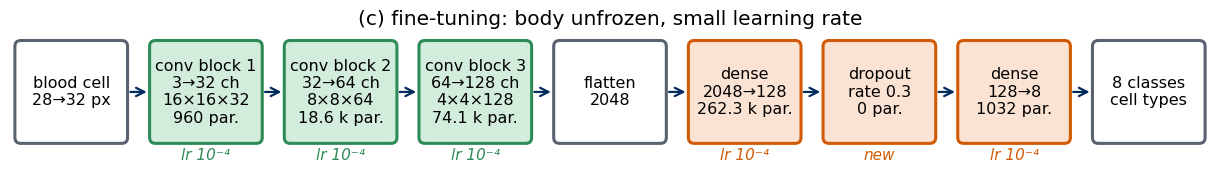

In [17]:
m_ft = copy.deepcopy(demo); set_trainable(m_ft.body, True)
param_table(m_ft, "fine-tuning (c): everything trained, learning rate 1e-4")
stage_table(m_ft, CIFAR_STAGES, "per stage, fine-tuning (c)")
total = draw_blocks([dict(name="blood cell", detail="28→32 px", status="data")] + cifar_body_blocks(m_ft, X32, "unfrozen", "lr 10⁻⁴")
                    + new_head_boxes(m_ft, "lr 10⁻⁴"), "(c) fine-tuning: body unfrozen, small learning rate",
                    os.path.join(RESULTS, "Lab_014a_arch_cifar_finetune.png"))
assert total == count_params(m_ft)

In [18]:
EPOCHS_A, MIN_STEPS_A = 20, 300                 # (a): 20 epochs, at least 300 steps; (b) twice as many; (c) as many again
METHODS_A = {"frozen": "(a) frozen CIFAR-10 body + new layers",
             "random": "(b) random initialisation",
             "finetune": "(c) (a) + fine-tuning, learning rate / 10"}
acc_A = {m: [] for m in METHODS_A}; time_A = {m: [] for m in METHODS_A}; models_A = {}

for n in BUDGETS:
    Xs, ys = Xa_sub[POS[n]], ya_sub[POS[n]]
    S = n_steps(n, EPOCHS_A, MIN_STEPS_A)
    # (a) frozen body, new layers trained
    torch.manual_seed(0)
    ma = TransferNet(copy.deepcopy(cifar_cnn.body)); set_trainable(ma.body, False)
    before, c_before = copy.deepcopy(ma.body.state_dict()), checksum(ma.body)
    t_a, l_a = train_steps(ma, ma.head.parameters(), 1e-3, Xs, ys, S, eval_modules=[ma.body])
    assert same_state(before, ma.body.state_dict()), "the frozen body changed"
    # (b) the same architecture, random initialisation, everything trained
    torch.manual_seed(0)
    mb = TransferNet(CifarCNN(regularise=True).body)
    t_b, l_b = train_steps(mb, mb.parameters(), 1e-3, Xs, ys, 2 * S)
    # (c) continue from (a): unfreeze the body, train everything with a ten times smaller learning rate
    mc = copy.deepcopy(ma); set_trainable(mc.body, True)
    t_c, l_c = train_steps(mc, mc.parameters(), 1e-4, Xs, ys, S, seed=1)
    t_c += t_a
    assert not same_state(before, mc.body.state_dict())
    for m, model, t in [("frozen", ma, t_a), ("random", mb, t_b), ("finetune", mc, t_c)]:
        acc_A[m].append(accuracy(model, Xa_te, ya_te)); time_A[m].append(t)
        if n == 100: models_A[m] = model
    print(f"n = {n}: {S} steps ({S * 64 / (8 * n):.0f} epochs) for (a), {2 * S} for (b), {S} more for (c);"
          f" body checksum before {c_before:.6f}, after {checksum(ma.body):.6f}")
    print(f"   final training loss  (a) {l_a:.3f}   (b) {l_b:.3f}   (c) {l_c:.3f}")
    print(f"   test accuracy        (a) {100 * acc_A['frozen'][-1]:.1f}%   (b) {100 * acc_A['random'][-1]:.1f}%   (c) {100 * acc_A['finetune'][-1]:.1f}%")

n = 10: 300 steps (240 epochs) for (a), 600 for (b), 300 more for (c); body checksum before 6144.644710, after 6144.644710
   final training loss  (a) 0.023   (b) 0.001   (c) 0.010
   test accuracy        (a) 65.6%   (b) 72.7%   (c) 66.8%


n = 100: 300 steps (24 epochs) for (a), 600 for (b), 300 more for (c); body checksum before 6144.644710, after 6144.644710
   final training loss  (a) 0.266   (b) 0.083   (c) 0.242
   test accuracy        (a) 82.4%   (b) 83.2%   (c) 82.1%


n = 800: 2000 steps (20 epochs) for (a), 4000 for (b), 2000 more for (c); body checksum before 6144.644710, after 6144.644710
   final training loss  (a) 0.209   (b) 0.078   (c) 0.276
   test accuracy        (a) 88.9%   (b) 92.9%   (c) 91.0%


In [19]:
print(f"{'cells per type':>14s} | " + " | ".join(f"{METHODS_A[m]:>40s}" for m in METHODS_A))
for i, n in enumerate(BUDGETS):
    print(f"{n:14d} | " + " | ".join(f"{100 * acc_A[m][i]:33.1f}% ({time_A[m][i]:3.0f} s)" for m in METHODS_A))

cells per type |    (a) frozen CIFAR-10 body + new layers |                (b) random initialisation | (c) (a) + fine-tuning, learning rate / 10
            10 |                              65.6% (  2 s) |                              72.7% ( 14 s) |                              66.8% (  9 s)
           100 |                              82.4% (  2 s) |                              83.2% ( 14 s) |                              82.1% (  9 s)
           800 |                              88.9% ( 13 s) |                              92.9% ( 95 s) |                              91.0% ( 61 s)


saved figures/transfer_partA_blood.png


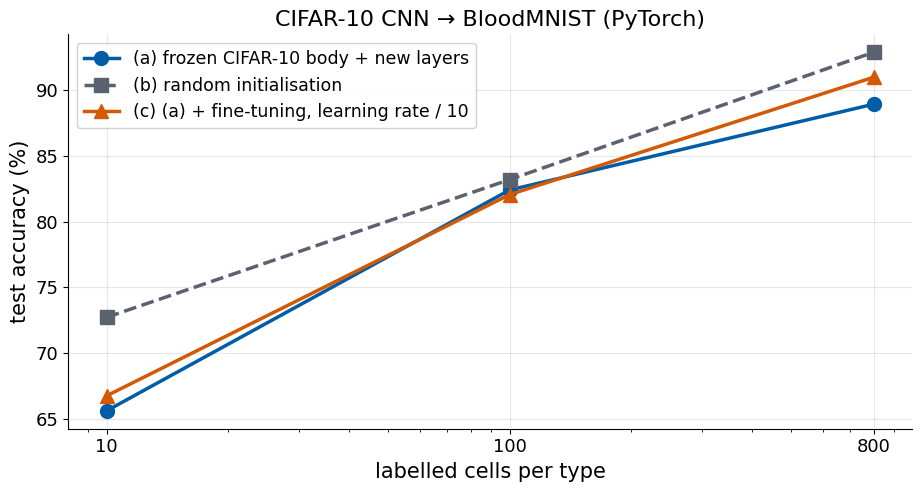

In [20]:
def plot_budget(curves, title, path=None):
    # curves: list of (label, accuracies at BUDGETS, colour, marker, linestyle); large fonts for slides
    with plt.rc_context({"font.size": 16, "legend.fontsize": 12.5}):
        fig, ax = plt.subplots(figsize=(9.5, 5.2))
        for lab, acc, c, mk, ls in curves:
            ax.plot(BUDGETS, 100 * np.asarray(acc), marker=mk, ls=ls, color=c, lw=2.5, ms=10, label=lab)
        ax.set_xscale("log"); ax.set_xticks(BUDGETS); ax.set_xticklabels([str(b) for b in BUDGETS])
        ax.set_xlabel("labelled cells per type"); ax.set_ylabel("test accuracy (%)")
        ax.set_title(title); ax.grid(alpha=0.3); ax.legend(loc="best", framealpha=0.9)
        fig.tight_layout()
        if path: fig.savefig(path, dpi=200); print("saved", path)
        plt.show()

plot_budget([(METHODS_A["frozen"], acc_A["frozen"], UJBlue, "o", "-"),
             (METHODS_A["random"], acc_A["random"], UJGray, "s", "--"),
             (METHODS_A["finetune"], acc_A["finetune"], DSOrange, "^", "-")],
            "CIFAR-10 CNN → BloodMNIST (PyTorch)", os.path.join(FIGS, "transfer_partA_blood.png"))

Transfer from our own CIFAR-10 network does not pay off on blood cells. Training the same architecture from random initialisation (b) is the best of the three at every budget: 72.7%, 83.2% and 92.9% at 10, 100 and 800 cells per type, against 65.6%, 82.4% and 88.9% for the frozen body (a) and 66.8%, 82.1% and 91.0% after fine-tuning (c). Fine-tuning recovers part of the gap at 800 per type, where 2000 extra steps let the body adapt, but never closes it. The final training losses (0.001 to 0.08 for (b), 0.02 to 0.27 for (a)) show that (b) fits its labelled cells best, and the test accuracy follows. The CIFAR-10 body was trained on only 10 000 photographs and its 94 thousand parameters are few; the network is small enough to be trained on 80 labelled cells without collapsing, and features learned on cars and frogs, applied to inputs with the wrong colour statistics, are worse than features learned directly on the cells. It is the counterexample of Lab 013 again, now on a harder target: a small, weakly trained source network is not a useful prior.

### Confusion matrices

The confusion matrix counts $C_{ab}$, the number of test cells of true type $a$ predicted as type $b$; colours show each row divided by its sum, so the diagonal is the recall of each type. We show the three models trained on 100 cells per type and save their weights.

(a) frozen CIFAR-10 body + new layers      recall per type [0.77 0.91 0.8  0.62 0.85 0.64 0.91 0.98]; most frequent error immature granulocyte -> monocyte (80 of 579)
   saved results/Lab_014a_cifar_cnn_frozen_100_per_type.pt


(b) random initialisation                  recall per type [0.46 0.93 0.9  0.58 0.86 0.91 0.92 0.99]; most frequent error immature granulocyte -> monocyte (176 of 579)
   saved results/Lab_014a_cifar_cnn_random_100_per_type.pt


(c) (a) + fine-tuning, learning rate / 10  recall per type [0.87 0.89 0.85 0.45 0.88 0.75 0.94 0.98]; most frequent error immature granulocyte -> basophil (126 of 579)
   saved results/Lab_014a_cifar_cnn_finetune_100_per_type.pt


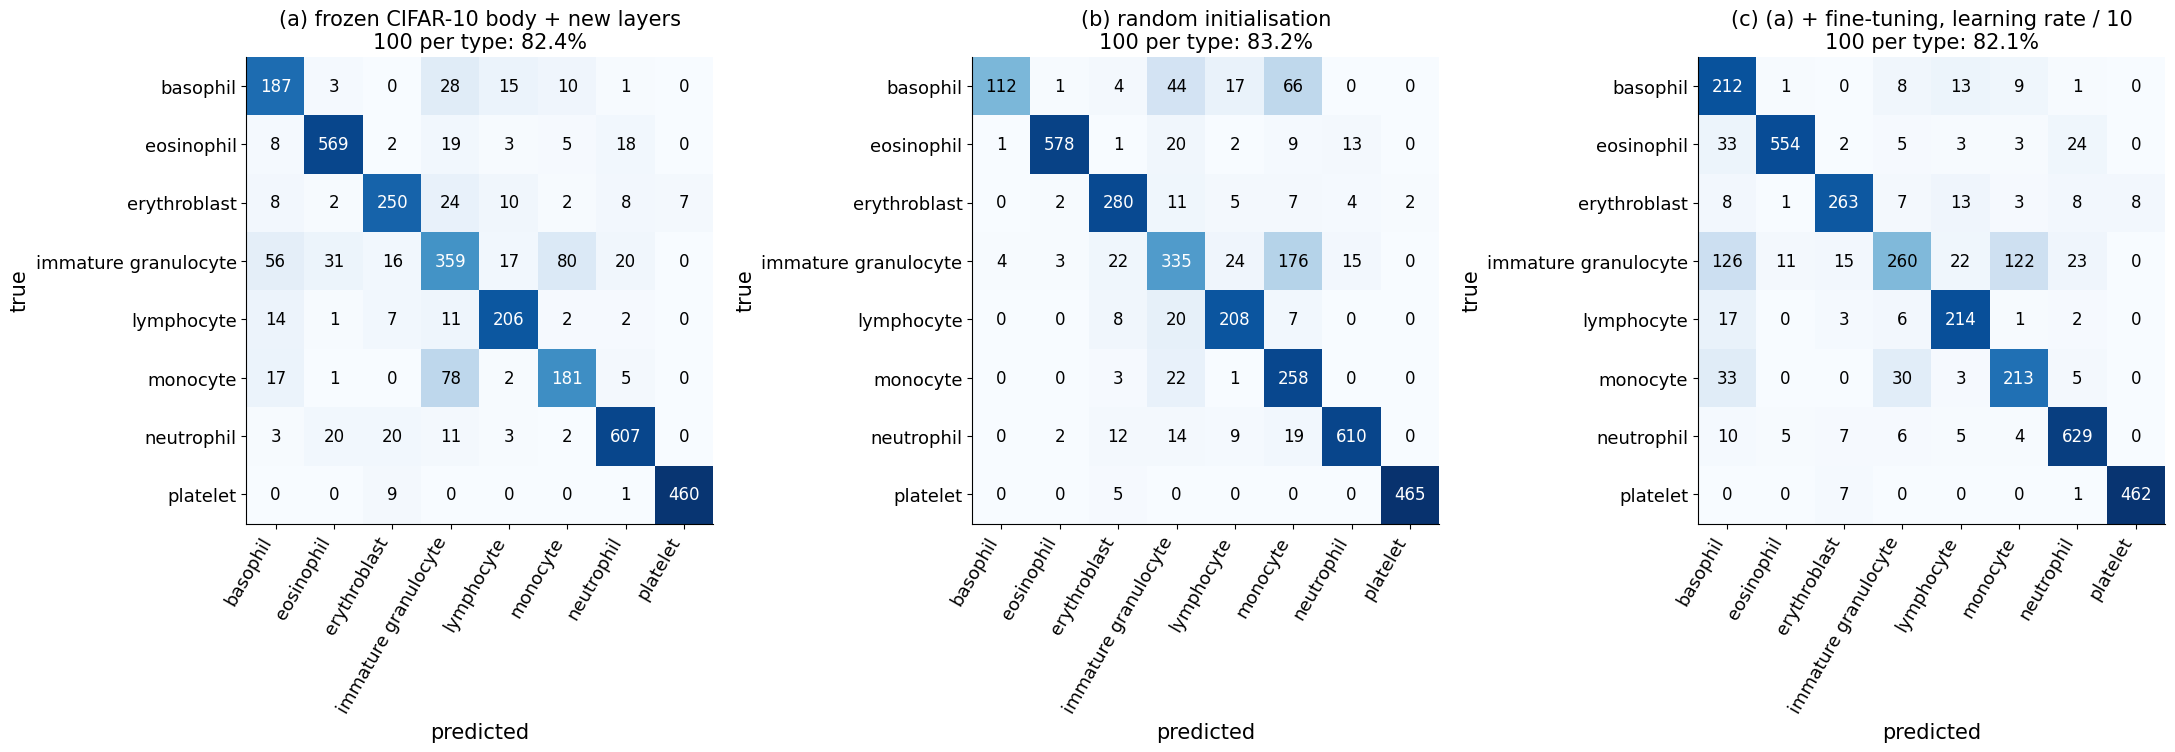

In [21]:
def confusion_matrix(y_true, y_pred, n=8):
    cm = np.zeros((n, n), dtype=int)
    np.add.at(cm, (np.asarray(y_true), np.asarray(y_pred)), 1)
    return cm

def plot_confusion(ax, cm, labels, title):
    # rows: true class, columns: predicted class; colour = fraction of the row, numbers = counts
    frac = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)
    for a in range(len(labels)):
        for b in range(len(labels)):
            ax.text(b, a, cm[a, b], ha="center", va="center", fontsize=12, color="white" if frac[a, b] > 0.5 else "black")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=13)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=13)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=15)

def most_confused(cm):
    off = cm - np.diag(np.diag(cm)); a, b = np.unravel_index(off.argmax(), off.shape)
    return f"{BLOOD_TYPES[a]} -> {BLOOD_TYPES[b]} ({off[a, b]} of {cm[a].sum()})"

fig, axes = plt.subplots(1, 3, figsize=(22, 8))
for ax, m in zip(axes, METHODS_A):
    pred = predict(models_A[m], Xa_te).argmax(1).numpy()
    cm = confusion_matrix(yb_te, pred)
    plot_confusion(ax, cm, BLOOD_TYPES, f"{METHODS_A[m]}\n100 per type: {100 * (pred == yb_te).mean():.1f}%")
    print(f"{METHODS_A[m]:42s} recall per type {np.round(np.diag(cm) / cm.sum(1), 2)}; most frequent error {most_confused(cm)}")
    path = os.path.join(RESULTS, f"Lab_014a_cifar_cnn_{m}_100_per_type.pt")
    torch.save(models_A[m].state_dict(), path); print("   saved", path)
plt.tight_layout(); plt.show()

The weakest class is the same in all three models: immature granulocytes, with recall 0.62, 0.58 and 0.45 for (a), (b) and (c), confused mostly with monocytes (80 and 176 of 579 test cells in (a) and (b)) and, after fine-tuning, with basophils (126). These are the cells that are morphologically closest to each other: large, with a big nucleus and granular cytoplasm. The models differ elsewhere: (b) recognises only 46% of basophils, (a) only 64% of monocytes, and (c) trades a better basophil recall (0.87) for a worse one on immature granulocytes. Platelets, small and anucleate, are recognised almost perfectly by every model.

## 3. A pretrained ResNet-18

The second source network is downloaded. ResNet-18 is the smallest residual network of K. He, X. Zhang, S. Ren and J. Sun, *Deep Residual Learning for Image Recognition*, CVPR 2016, pp. 770–778, [doi:10.1109/CVPR.2016.90](https://doi.org/10.1109/CVPR.2016.90), [arXiv:1512.03385](https://arxiv.org/abs/1512.03385). Its weights in `torchvision` were trained on ImageNet-1k, about 1.28 million photographs in 1000 classes, at $224\times224$ pixels. Compared with the CIFAR-10 network of Section 2 it has a hundred times more parameters and was trained on a hundred times more images; the question is whether features learned on photographs of dogs, cars and mushrooms help with blood cells.

ImageNet (J. Deng, W. Dong, R. Socher, L.-J. Li, K. Li, L. Fei-Fei, *ImageNet: A large-scale hierarchical image database*, CVPR 2009, pp. 248–255, [doi:10.1109/CVPR.2009.5206848](https://doi.org/10.1109/CVPR.2009.5206848)) is a collection of photographs organised by the noun hierarchy of WordNet. The subset used for the ImageNet Large Scale Visual Recognition Challenge (O. Russakovsky et al., International Journal of Computer Vision 115, 211 (2015), [doi:10.1007/s11263-015-0816-y](https://doi.org/10.1007/s11263-015-0816-y), [arXiv:1409.0575](https://arxiv.org/abs/1409.0575)), called ImageNet-1k, has 1 281 167 training images, 50 000 validation images and 1000 classes, listed on [image-net.org](https://www.image-net.org/download.php). The classes are everyday objects, animals, plants, food and scenes, with a strong share of fine-grained categories such as breeds of dogs; photographs vary in size and are typically a few hundred pixels wide. The images may be used for non-commercial research and education under the ImageNet terms of access. A pretrained ResNet-18 has therefore seen many textures, colours and shapes, but no microscope images of stained blood. Twenty class names drawn at random give an impression of its world.

### Downloading the weights

`ResNet18_Weights.IMAGENET1K_V1` names one set of trained weights; passing it to `torchvision.models.resnet18` downloads the file (about 45 MB) on the first call and loads it. The object also carries metadata: the accuracy on the ImageNet validation set, the class names, and the preprocessing used during training.

In [22]:
weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
resnet = torchvision.models.resnet18(weights=weights).eval()      # downloads about 45 MB on the first call
print("ImageNet results stored with the weights:", weights.meta["_metrics"])
print("number of parameters:", weights.meta["num_params"], "| number of ImageNet classes:", len(weights.meta["categories"]))
print("preprocessing used for these weights:", weights.transforms())
print("twenty ImageNet classes drawn at random:", ", ".join(np.random.default_rng(1).choice(weights.meta["categories"], 20, replace=False)))

ImageNet results stored with the weights: {'ImageNet-1K': {'acc@1': 69.758, 'acc@5': 89.078}}
number of parameters: 11689512 | number of ImageNet classes: 1000
preprocessing used for these weights: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
twenty ImageNet classes drawn at random: Great Dane, maraca, eft, red wolf, dowitcher, printer, buckle, broccoli, quail, Band Aid, mashed potato, clog, toilet seat, space shuttle, leatherback turtle, steel drum, fly, ambulance, Leonberg, entertainment center


### Architecture and parameter count

Printing the model lists its modules in order. Each `BasicBlock` is a residual block: two $3\times3$ convolutions with batch normalisation form a function $F$, whose result is added to the block's input before the last ReLU,
$$x\;\mapsto\;\mathrm{ReLU}\big(x+F(x)\big), \tag{6}$$
when a block halves the image size and doubles the channels, the input passes through a $1\times1$ convolution with stride 2 (`downsample`) so that the two terms of the sum have the same shape.

In [23]:
print(resnet)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

The network is organised in stages: a stem (`conv1`, a $7\times7$ convolution with stride 2, `bn1`, ReLU and a $3\times3$ max pooling with stride 2), four stages `layer1` to `layer4` of two residual blocks each, global average pooling (`avgpool`) and one dense layer `fc` from 512 features to the 1000 ImageNet classes. We count the parameters of each stage and follow the shape of one input of $224\times224$ pixels, the ImageNet size, and of $64\times64$ pixels, the BloodMNIST size.

In [24]:
STAGES = ["conv1", "bn1", "layer1", "layer2", "layer3", "layer4", "fc"]
print(f"{'stage':8s} {'parameters':>11s} {'fraction':>9s}")
for s in STAGES:
    k = count_params(getattr(resnet, s))
    print(f"{s:8s} {k:11d} {100 * k / count_params(resnet):8.1f}%")
assert sum(count_params(getattr(resnet, s)) for s in STAGES) == count_params(resnet) == weights.meta["num_params"]

@torch.no_grad()
def stage_shapes(model, size):
    x = torch.zeros(1, 3, size, size)
    out = {}
    x = model.maxpool(model.relu(model.bn1(model.conv1(x)))); out["stem"] = tuple(x.shape)
    for s in ["layer1", "layer2", "layer3", "layer4", "avgpool"]:
        x = getattr(model, s)(x); out[s] = tuple(x.shape)
    return out

s224, s64 = stage_shapes(resnet, 224), stage_shapes(resnet, 64)
print(f"\n{'after':8s} {'224 x 224 input':>20s} {'64 x 64 input':>20s}")
for k in s224: print(f"{k:8s} {str(s224[k]):>20s} {str(s64[k]):>20s}")

stage     parameters  fraction
conv1           9408      0.1%
bn1              128      0.0%
layer1        147968      1.3%
layer2        525568      4.5%
layer3       2099712     18.0%
layer4       8393728     71.8%
fc            513000      4.4%

after         224 x 224 input        64 x 64 input
stem          (1, 64, 56, 56)      (1, 64, 16, 16)
layer1        (1, 64, 56, 56)      (1, 64, 16, 16)
layer2       (1, 128, 28, 28)       (1, 128, 8, 8)
layer3       (1, 256, 14, 14)       (1, 256, 4, 4)
layer4         (1, 512, 7, 7)       (1, 512, 2, 2)
avgpool        (1, 512, 1, 1)       (1, 512, 1, 1)


Seventy-two per cent of the 11.7 million parameters sit in `layer4`, and only 0.1% in the stem; the output layer for 1000 classes holds another 4.4%. On a $224\times224$ image the last stage works on a $7\times7$ grid; on our $64\times64$ cells it works on a $2\times2$ grid, so each of its units sees almost the whole cell. Average pooling turns both into the same 512 features.

The block diagram summarises the network as it was trained on ImageNet: stem, four residual stages, average pooling and the output layer with 1000 classes, each block with the number of its parameters. Seventy-two per cent of the parameters sit in `layer4`.

saved results/Lab_014a_arch_resnet18_source.png


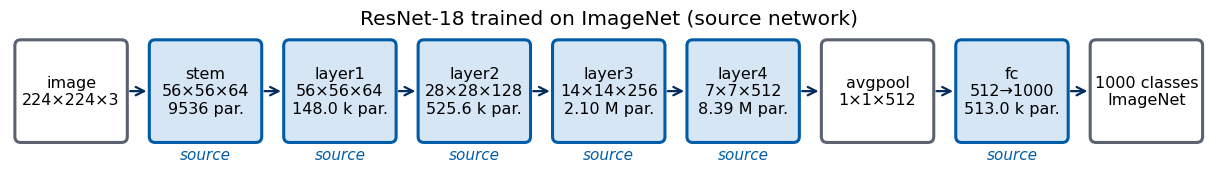

In [25]:
STAGE_MODS = [("stem", ["conv1", "bn1"], "maxpool"), ("layer1", ["layer1"], "layer1"), ("layer2", ["layer2"], "layer2"),
              ("layer3", ["layer3"], "layer3"), ("layer4", ["layer4"], "layer4")]
SH = {size: hook_shapes(resnet, torch.zeros(1, 3, size, size), [o for _, _, o in STAGE_MODS] + ["avgpool"]) for size in (224, 64)}

def resnet_blocks(model, status_of, tag_of=lambda s: None, size=64):
    # one box per stage: output shape for a size x size input and parameter count, both read from the model
    return [dict(name=s, detail=SH[size][o], params=sum(count_params(model.get_submodule(m)) for m in mods), status=status_of(s),
                 **({"tag": tag_of(s)} if tag_of(s) else {})) for s, mods, o in STAGE_MODS]

def fc_box(model, status, tag=None, **kw):
    return dict(name="fc", detail=f"{model.fc.in_features}→{model.fc.out_features}", params=count_params(model.fc), status=status,
                **({"tag": tag} if tag else {}), **kw)

TOTAL_RESNET = draw_blocks([dict(name="image", detail="224×224×3", status="data")] + resnet_blocks(resnet, lambda s: "source", size=224)
                           + [dict(name="avgpool", detail=SH[224]["avgpool"], status="data"), fc_box(resnet, "source"),
                              dict(name=f"{resnet.fc.out_features} classes", detail="ImageNet", status="data")],
                           "ResNet-18 trained on ImageNet (source network)", os.path.join(RESULTS, "Lab_014a_arch_resnet18_source.png"))
assert TOTAL_RESNET == count_params(resnet)

`torchinfo.summary` prints the same information layer by layer, with the output shape of every layer for one input image.

In [26]:
try:
    from torchinfo import summary
    info = summary(resnet, input_size=(1, 3, 64, 64), col_names=("output_size", "num_params"), depth=1, verbose=0)
    print(info)
    assert info.total_params == TOTAL_RESNET, "diagram and torchinfo disagree"
    print(f"diagram total {TOTAL_RESNET:,} parameters = torchinfo total {info.total_params:,}")
except ImportError:
    print("torchinfo is not installed: pip install torchinfo")

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 1000]                 --
├─Conv2d: 1-1                            [1, 64, 32, 32]           9,408
├─BatchNorm2d: 1-2                       [1, 64, 32, 32]           128
├─ReLU: 1-3                              [1, 64, 32, 32]           --
├─MaxPool2d: 1-4                         [1, 64, 16, 16]           --
├─Sequential: 1-5                        [1, 64, 16, 16]           147,968
├─Sequential: 1-6                        [1, 128, 8, 8]            525,568
├─Sequential: 1-7                        [1, 256, 4, 4]            2,099,712
├─Sequential: 1-8                        [1, 512, 2, 2]            8,393,728
├─AdaptiveAvgPool2d: 1-9                 [1, 512, 1, 1]            --
├─Linear: 1-10                           [1, 1000]                 513,000
Total params: 11,689,512
Trainable params: 11,689,512
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 148.57
In

### First-layer kernels

`resnet.conv1.weight` has shape $(64,3,7,7)$: 64 kernels, each with one $7\times7$ slice per input colour. Reordered to $(64,7,7,3)$ and each rescaled to $[0,1]$, a kernel can be shown as a small colour image. To quantify what we see, we compute for every kernel the mean correlation between its red, green and blue slices: close to 1 for a kernel that treats the three colours alike (a brightness pattern), small or negative for a kernel that compares colours.

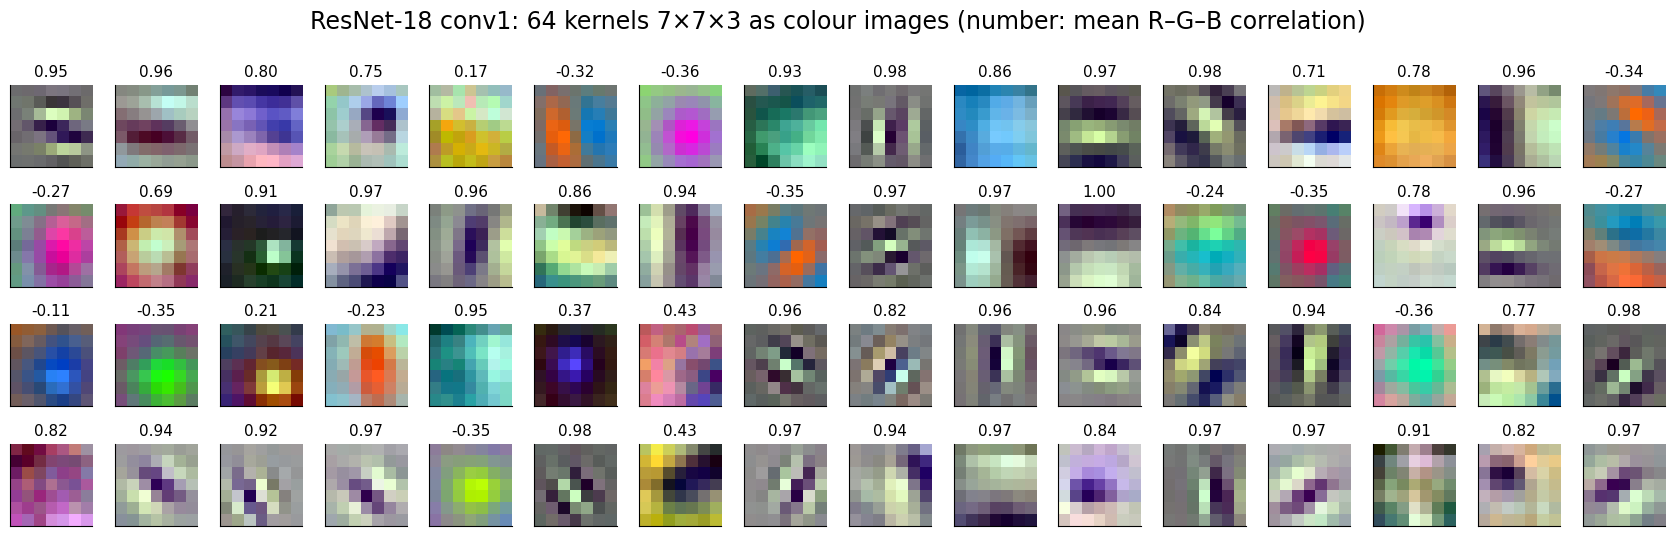

kernels with R-G-B correlation > 0.8: 40, < 0.3: 15 of 64


In [27]:
def normalise01(w):
    # rescale each kernel (first axis) separately to [0, 1]
    w = np.asarray(w, dtype=np.float64)
    lo = w.reshape(len(w), -1).min(1).reshape(-1, *[1] * (w.ndim - 1)); hi = w.reshape(len(w), -1).max(1).reshape(-1, *[1] * (w.ndim - 1))
    return (w - lo) / (hi - lo + 1e-12)

K1 = resnet.conv1.weight.detach().permute(0, 2, 3, 1).numpy()          # (64, 7, 7, 3) = (kernel, row, column, colour)
def colour_correlation(K):
    # mean pairwise correlation between the R, G, B slices of each kernel
    S = K.reshape(len(K), -1, 3)
    return np.array([np.mean([np.corrcoef(s[:, i], s[:, j])[0, 1] for i, j in [(0, 1), (0, 2), (1, 2)]]) for s in S])
rgb_corr = colour_correlation(K1)

fig, axes = plt.subplots(4, 16, figsize=(17, 5.6))
for o, a in enumerate(axes.ravel()):
    a.imshow(normalise01(K1)[o], interpolation="nearest"); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"{rgb_corr[o]:.2f}", fontsize=11)
fig.suptitle("ResNet-18 conv1: 64 kernels 7×7×3 as colour images (number: mean R–G–B correlation)")
plt.tight_layout(); plt.show()
print(f"kernels with R-G-B correlation > 0.8: {np.sum(rgb_corr > 0.8)}, < 0.3: {np.sum(rgb_corr < 0.3)} of 64")

The 64 first-layer kernels fall into two groups. Forty have a correlation above 0.8 between their colour slices: they respond to brightness patterns, and many are oriented edge and bar detectors at several angles, or checkerboard-like detectors of fine texture. Fifteen have a correlation below 0.3, some strongly negative: they are colour-opponent blobs and edges (blue against orange, green against magenta). These are the generic features that make ImageNet networks transferable; they resemble the receptive fields of simple cells in the primary visual cortex.

### ImageNet normalisation and 64-pixel inputs

`weights.transforms()` lists the preprocessing of the training: resize to 256 pixels, crop the central $224\times224$ pixels, scale to $[0,1]$, and standardise each channel as in equation (4) with the ImageNet means $(0.485, 0.456, 0.406)$ and standard deviations $(0.229, 0.224, 0.225)$. We keep the standardisation, because the first layer and the batch-normalisation statistics expect it, but not the resizing: we use the $64\times64$ version of BloodMNIST directly. The network accepts any image size thanks to its last pooling layer, `AdaptiveAvgPool2d((1, 1))`, which averages each of the 512 final feature maps over whatever spatial size it has, $2\times2$ for a $64\times64$ input instead of $7\times7$ for $224\times224$. The price is a change of scale: at 64 pixels a cell covers far fewer pixels than objects in ImageNet photographs did, the stem reduces it to $16\times16$ positions after two strides of 2, and the last stage sees only four positions. Enlarging the images to 128 pixels reduces this mismatch at four times the cost.

Shapes: `uint8` $(N,64,64,3)$ → `float32` $(N,3,64,64)$. The unchanged network with its 1000 ImageNet outputs, applied to 200 test cells, shows what it makes of blood cells.

In [28]:
T = weights.transforms()
IMNET_MEAN = torch.tensor(T.mean)[None, :, None, None]; IMNET_STD = torch.tensor(T.std)[None, :, None, None]

def blood_as_imagenet(X_raw):
    # uint8 (N, 64, 64, 3) -> float32 (N, 3, 64, 64) standardised with the ImageNet statistics
    X = torch.from_numpy(X_raw).permute(0, 3, 1, 2).float() / 255
    return (X - IMNET_MEAN) / IMNET_STD

X64_sub = blood_as_imagenet(b64["train_images"][SUB[800]]); y64_sub = torch.from_numpy(yb_tr[SUB[800]])
X64_te = blood_as_imagenet(b64["test_images"]); y64_te = torch.from_numpy(yb_te)
assert X64_sub.shape == (6400, 3, 64, 64) and X64_te.shape == (3421, 3, 64, 64)
print("ImageNet mean", T.mean, "std", T.std)
print("blood cells (64 px):", tuple(X64_sub.shape), " test:", tuple(X64_te.shape))

with torch.no_grad():
    top = resnet(X64_te[:200]).argmax(1)
names, counts = np.unique([weights.meta["categories"][i] for i in top], return_counts=True)
print("ImageNet classes predicted by the unchanged network for 200 blood cells:",
      ", ".join(f"{n} ({c})" for n, c in sorted(zip(names, counts), key=lambda t: -t[1])[:5]))

ImageNet mean [0.485, 0.456, 0.406] std [0.229, 0.224, 0.225]
blood cells (64 px): (6400, 3, 64, 64)  test: (3421, 3, 64, 64)
ImageNet classes predicted by the unchanged network for 200 blood cells: golf ball (64), rubber eraser (19), face powder (14), remote control (14), honeycomb (13)


Without a new head the network answers in ImageNet terms: 64 of 200 blood cells are called "golf ball", followed by "rubber eraser", "face powder", "remote control" and "honeycomb", round or textured objects of similar appearance. The predictions are meaningless as labels, but they show that the features respond to roundness and fine texture, which is what distinguishes cell types.

### Stored outputs of the frozen layers

Since the frozen layers do not change and the images are not augmented, their output for a given image is the same in every training step, and it is wasteful to recompute it. We pass the 6400 labelled images of the largest subset and the 3421 test images through the frozen network once, in evaluation mode, and store two arrays: the output of `layer3`, shape $(N,256,4,4)$, needed for fine-tuning `layer4`, and the 512 pooled features after `layer4`, shape $(N,512)$, which are exactly the features $h$ of equation (1) that enter the output layer. Training on stored arrays is exact, not an approximation; the trained weights of both routes agree to rounding.

In [29]:
@torch.no_grad()
def trunk_and_features(model, X, size=None, keep_h3=True, batch=256):
    # frozen network in evaluation mode: layer3 outputs (N, 256, s/16, s/16) and the 512 pooled features (N, 512)
    model.eval(); H3, Fs = [], []
    for k in range(0, len(X), batch):
        x = X[k:k + batch]
        if size is not None: x = F.interpolate(x, size=(size, size), mode="bilinear", align_corners=False)
        h = model.maxpool(model.relu(model.bn1(model.conv1(x))))
        h3 = model.layer3(model.layer2(model.layer1(h)))
        Fs.append(torch.flatten(model.avgpool(model.layer4(h3)), 1))
        if keep_h3: H3.append(h3)
    return (torch.cat(H3) if keep_h3 else None), torch.cat(Fs)

t0 = time.time(); H3_sub, F_sub = trunk_and_features(resnet, X64_sub); T_EXTRACT_SUB = time.time() - t0
t0 = time.time(); H3_te, F_te = trunk_and_features(resnet, X64_te); T_EXTRACT_TE = time.time() - t0
assert H3_sub.shape == (6400, 256, 4, 4) and F_sub.shape == (6400, 512)
MS_PER_IMAGE = 1000 * (T_EXTRACT_SUB + T_EXTRACT_TE) / (len(X64_sub) + len(X64_te))
print(f"stored: layer3 outputs {tuple(H3_sub.shape)}, features {tuple(F_sub.shape)}")
print(f"time: {T_EXTRACT_SUB:.1f} s for {len(X64_sub)} training images, {T_EXTRACT_TE:.1f} s for {len(X64_te)} test images"
      f" ({MS_PER_IMAGE:.1f} ms per image)")

class Top(nn.Module):
    # the end of the network: layer4, average pooling, fc (shares the modules of `model`)
    def __init__(self, model):
        super().__init__()
        self.layer4, self.avgpool, self.fc = model.layer4, model.avgpool, model.fc
    def forward(self, h3):                      # (N, 256, 4, 4) -> (N, 512, 2, 2) -> (N, 512) -> (N, 8)
        return self.fc(torch.flatten(self.avgpool(self.layer4(h3)), 1))

stored: layer3 outputs (6400, 256, 4, 4), features (6400, 512)
time: 5.6 s for 6400 training images, 2.8 s for 3421 test images (0.8 ms per image)


### New head on the frozen network

The recipe has three lines: replace the output layer, `model.fc = nn.Linear(512, 8)`; set `requires_grad=False` for all other parameters; give only `model.fc.parameters()` to the optimiser. Because no layer except `fc` is trained, the whole network stays in evaluation mode, so batch normalisation uses its ImageNet running statistics. Trained through the whole network, every step repeats the forward pass of 11 million frozen parameters for 64 images; trained on the stored features, a step costs a $64\times512$ by $512\times8$ matrix product. To show that the two are the same computation, two copies trained for 50 steps with the same mini-batches, one through the full network and one on the stored features, and compares the resulting weights and the times.

In [30]:
def resnet_new_head(seed=0):
    # a copy of the pretrained network with a new 512 -> 8 output layer; everything except fc frozen
    torch.manual_seed(seed)
    m = copy.deepcopy(resnet)
    m.fc = nn.Linear(512, len(BLOOD_TYPES))
    set_trainable(m, False); set_trainable(m.fc, True)
    return m

def frozen_part(m):
    # every entry of the state dict except the new output layer
    return {k: v.clone() for k, v in m.state_dict().items() if not k.startswith("fc.")}

n, S_DEMO = 10, 50
m_full, m_cached = resnet_new_head(), resnet_new_head()
print(f"trainable: {sum(p.numel() for p in m_full.parameters() if p.requires_grad)} of {count_params(m_full)} parameters")
before = frozen_part(m_full)
t_full, _ = train_steps(m_full, m_full.fc.parameters(), 1e-3, X64_sub[POS[n]], y64_sub[POS[n]], S_DEMO, eval_modules=[m_full])
t_cached, _ = train_steps(m_cached.fc, m_cached.fc.parameters(), 1e-3, F_sub[POS[n]], y64_sub[POS[n]], S_DEMO)
assert same_state(before, frozen_part(m_full)), "the frozen network changed"
assert torch.allclose(m_full.fc.weight, m_cached.fc.weight, atol=1e-4) and torch.allclose(m_full.fc.bias, m_cached.fc.bias, atol=1e-4)
print(f"{S_DEMO} steps through the whole frozen network: {t_full:.1f} s; on the stored features: {t_cached:.2f} s;"
      f" largest difference of the trained fc weights {(m_full.fc.weight - m_cached.fc.weight).abs().max():.1e}")
print(f"frozen part unchanged, checksum {sum(v.double().abs().sum().item() for v in before.values()):.4f}")

trainable: 4104 of 11180616 parameters


50 steps through the whole frozen network: 2.7 s; on the stored features: 0.03 s; largest difference of the trained fc weights 0.0e+00
frozen part unchanged, checksum 169747.5759


The surgery on ResNet-18 removes the output layer for the 1000 ImageNet classes, with 513 000 parameters, and puts in its place a dense layer with 8 outputs and 4104 parameters; everything else is frozen.

pretrained ResNet-18 before the surgery
layer                   parameters  status
conv1                        9,408  trained
bn1                            128  trained
layer1                     147,968  trained
layer2                     525,568  trained
layer3                   2,099,712  trained
layer4                   8,393,728  trained
fc                         513,000  trained
trainable               11,689,512
frozen                           0

after replacing fc and freezing everything else
layer                   parameters  status
conv1                        9,408  frozen
bn1                            128  frozen
layer1                     147,968  frozen
layer2                     525,568  frozen
layer3                   2,099,712  frozen
layer4                   8,393,728  frozen
fc                           4,104  trained
trainable                    4,104
frozen                  11,176,512

per stage, after the surgery (64×64 input)
stage           output shape  p

saved results/Lab_014a_arch_resnet18_frozen.png


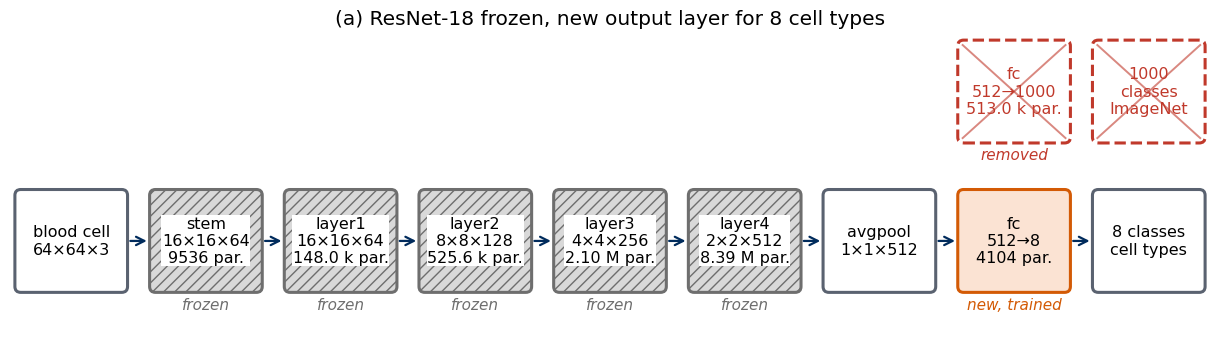

saved results/Lab_014a_torchview_resnet18_frozen.png


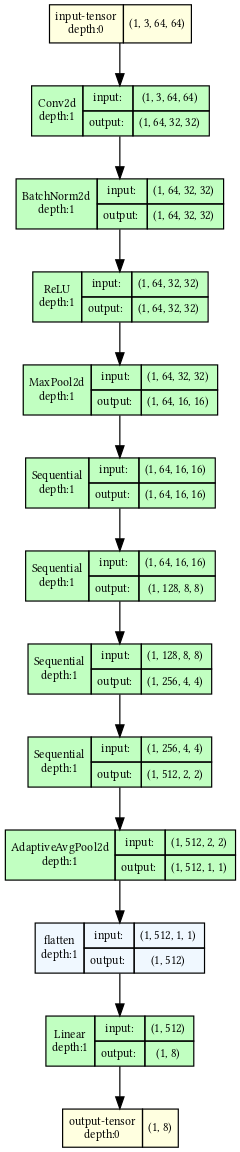

In [31]:
param_table(resnet, "pretrained ResNet-18 before the surgery", depth=1)
param_table(m_full, "after replacing fc and freezing everything else", depth=1)
RESNET_STAGES = [(s, SH[64][o], mods) for s, mods, o in STAGE_MODS] + [("fc", hook_shapes(m_full, torch.zeros(1, 3, 64, 64), ["fc"])["fc"], ["fc"])]
stage_table(m_full, RESNET_STAGES, "per stage, after the surgery (64×64 input)")

def new_fc_boxes(model, tag=None):
    return [dict(name="avgpool", detail=SH[64]["avgpool"], status="data"), fc_box(model, "new", tag),
            dict(name=f"{model.fc.out_features} classes", detail="cell types", status="data")]

total = draw_blocks([dict(name="blood cell", detail="64×64×3", status="data")] + resnet_blocks(m_full, lambda s: "frozen", lambda s: "frozen")
                    + new_fc_boxes(m_full) + [fc_box(resnet, "removed", "removed", row=1, at=7),
                                              dict(name=f"{resnet.fc.out_features}\nclasses", detail="ImageNet", status="removed", row=1, at=8, tag="")],
                    "(a) ResNet-18 frozen, new output layer for 8 cell types", os.path.join(RESULTS, "Lab_014a_arch_resnet18_frozen.png"))
assert total == count_params(m_full)
try:
    from torchview import draw_graph
    from IPython.display import Image, display
    g = draw_graph(m_full, input_size=(1, 3, 64, 64), depth=1, graph_name="transfer_resnet18")
    path = g.visual_graph.render(os.path.join(RESULTS, "Lab_014a_torchview_resnet18_frozen"), format="png", cleanup=True)
    print("saved", path); display(Image(path, width=300))
except Exception as e:                                   # torchview or graphviz missing
    print("torchview graph not drawn:", e)

In [32]:
EPOCHS_HEAD, MIN_STEPS_HEAD = 50, 500
acc_B, time_B, models_B = {}, {}, {}
for k in ["frozen", "layer4", "random", "logreg"]: acc_B[k], time_B[k] = [], []
for n in BUDGETS:
    S = n_steps(n, EPOCHS_HEAD, MIN_STEPS_HEAD)
    m = resnet_new_head()
    t, loss = train_steps(m.fc, m.fc.parameters(), 1e-3, F_sub[POS[n]], y64_sub[POS[n]], S)
    t += T_EXTRACT_SUB * len(SUB[n]) / len(SUB[800])                       # plus the feature extraction of these images
    acc = accuracy(m.fc, F_te, y64_te)
    acc_B["frozen"].append(acc); time_B["frozen"].append(t); models_B[("frozen", n)] = m
    print(f"n = {n:3d}: {S} steps ({S * 64 / (8 * n):.0f} epochs), final training loss {loss:.3f}, test accuracy {100 * acc:.1f}%")
assert torch.allclose(predict(m, X64_te[:64]), m.fc(F_te[:64]), atol=1e-4)      # the full network gives the same logits

n =  10: 500 steps (400 epochs), final training loss 0.013, test accuracy 67.6%


n = 100: 625 steps (50 epochs), final training loss 0.153, test accuracy 78.0%


n = 800: 5000 steps (50 epochs), final training loss 0.201, test accuracy 86.6%


Training the output layer through the whole frozen network and training it on the stored features give identical weights (largest difference 0.0) at very different cost: 2.7 s against 0.03 s for 50 steps. With 50 epochs on the stored features the head reaches 67.6%, 78.0% and 86.6% at 10, 100 and 800 cells per type, with final training losses of 0.01 to 0.20, close to the logistic regression below. The frozen ImageNet features are clearly useful: with only 10 cells per type they already separate the classes better than chance by a wide margin, and the accuracy grows steadily with the number of labels.

The head is then trained on the stored features for 50 epochs, with a minimum of 500 steps, Adam with learning rate $10^{-3}$. The reported time includes the share of the feature extraction that belongs to the labelled images.

### Fine-tuning the last stage

Next we unfreeze `layer4`, the last residual stage (8.4 million parameters), and train it together with `fc`, starting from the models of the previous step, with learning rate $10^{-4}$ for 5 epochs and at least 200 steps. `layer4` is in training mode, so its batch normalisation uses mini-batch statistics, while everything before it stays frozen. Training runs on the stored `layer3` outputs through `layer4` → average pooling → `fc`, which is again exact.

For fine-tuning, `layer4` is unfrozen together with the new output layer, so that 8.4 million of the 11.2 million parameters are trained; the stem and the first three stages stay frozen.

fine-tuning (c): layer4 and fc trained, learning rate 1e-4
layer                   parameters  status
conv1                        9,408  frozen
bn1                            128  frozen
layer1                     147,968  frozen
layer2                     525,568  frozen
layer3                   2,099,712  frozen
layer4                   8,393,728  trained
fc                           4,104  trained
trainable                8,397,832
frozen                   2,782,784

per stage, fine-tuning (c) (64×64 input)
stage           output shape  parameters  trainable
stem                16×16×64       9,536  no
layer1              16×16×64     147,968  no
layer2               8×8×128     525,568  no
layer3               4×4×256   2,099,712  no
layer4               2×2×512   8,393,728  yes
fc                         8       4,104  yes
total                         11,180,616
trainable                      8,397,832
frozen                         2,782,784



saved results/Lab_014a_arch_resnet18_finetune.png


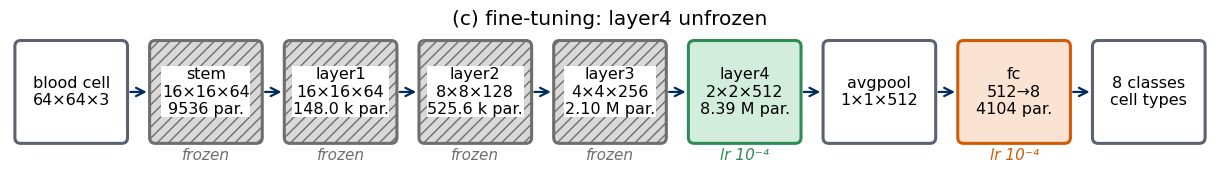

In [33]:
m_ft = copy.deepcopy(m_full); set_trainable(m_ft.layer4, True)
param_table(m_ft, "fine-tuning (c): layer4 and fc trained, learning rate 1e-4", depth=1)
stage_table(m_ft, RESNET_STAGES, "per stage, fine-tuning (c) (64×64 input)")
total = draw_blocks([dict(name="blood cell", detail="64×64×3", status="data")]
                    + resnet_blocks(m_ft, lambda s: "unfrozen" if s == "layer4" else "frozen", lambda s: "lr 10⁻⁴" if s == "layer4" else "frozen")
                    + new_fc_boxes(m_ft, "lr 10⁻⁴"), "(c) fine-tuning: layer4 unfrozen", os.path.join(RESULTS, "Lab_014a_arch_resnet18_finetune.png"))
assert total == count_params(m_ft)

In [34]:
EPOCHS_FT, MIN_STEPS_FT = 5, 200
for i, n in enumerate(BUDGETS):
    S = n_steps(n, EPOCHS_FT, MIN_STEPS_FT)
    mc = copy.deepcopy(models_B[("frozen", n)])                         # start from the trained new head
    set_trainable(mc.layer4, True)
    top = Top(mc)
    params = list(mc.layer4.parameters()) + list(mc.fc.parameters())
    before = {k: v.clone() for k, v in mc.state_dict().items() if not k.startswith(("layer4.", "fc."))}
    t, loss = train_steps(top, params, 1e-4, H3_sub[POS[n]], y64_sub[POS[n]], S, seed=1)
    assert same_state(before, {k: v for k, v in mc.state_dict().items() if not k.startswith(("layer4.", "fc."))})
    acc = accuracy(top, H3_te, y64_te)
    acc_B["layer4"].append(acc); time_B["layer4"].append(time_B["frozen"][i] + t); models_B[("layer4", n)] = mc
    print(f"n = {n:3d}: {S} steps ({S * 64 / (8 * n):.0f} epochs) in {t:5.1f} s, final training loss {loss:.3f},"
          f" test accuracy {100 * acc:.1f}% (new head alone: {100 * acc_B['frozen'][i]:.1f}%)")
assert torch.allclose(predict(mc, X64_te[:64]), predict(Top(mc), H3_te[:64]), atol=1e-4)

n =  10: 200 steps (160 epochs) in  12.9 s, final training loss 0.000, test accuracy 62.7% (new head alone: 67.6%)


n = 100: 200 steps (16 epochs) in  12.7 s, final training loss 0.002, test accuracy 81.4% (new head alone: 78.0%)


n = 800: 500 steps (5 epochs) in  36.2 s, final training loss 0.041, test accuracy 88.6% (new head alone: 86.6%)


Fine-tuning `layer4` helps when there are enough labels and hurts when there are not. With 10 cells per type the training loss drops to zero and the test accuracy falls from 67.6% to 62.7%: 8.4 million parameters memorise 80 images. With 100 per type the accuracy rises from 78.0% to 81.4%, with 800 per type from 86.6% to 88.6%. The rule of thumb that fine-tuning needs more data than freezing is visible here in one line of the table.

### ResNet-18 from random initialisation

The fair reference for (a) and (c) is the same ResNet-18 with random weights, all 11.2 million parameters trained on the labelled cells, Adam with learning rate $10^{-3}$, batch normalisation in training mode. Every step runs the full forward and backward pass, so this is the most expensive run of the notebook; it gets 3 epochs with a minimum of 300 steps, which is far less training than such a network would normally receive.

In [35]:
EPOCHS_RAND, MIN_STEPS_RAND = 3, 300
for n in BUDGETS:
    S = n_steps(n, EPOCHS_RAND, MIN_STEPS_RAND)
    torch.manual_seed(0)
    mr = torchvision.models.resnet18(weights=None, num_classes=len(BLOOD_TYPES))     # random weights, 8 outputs
    t, loss = train_steps(mr, mr.parameters(), 1e-3, X64_sub[POS[n]], y64_sub[POS[n]], S)
    acc = accuracy(mr, X64_te, y64_te)
    acc_B["random"].append(acc); time_B["random"].append(t); models_B[("random", n)] = mr
    print(f"n = {n:3d}: {S} steps ({S * 64 / (8 * n):.0f} epochs) in {t:5.1f} s ({t / S:.2f} s per step),"
          f" final training loss {loss:.3f}, test accuracy {100 * acc:.1f}%")

n =  10: 300 steps (240 epochs) in  59.7 s (0.20 s per step), final training loss 0.000, test accuracy 66.9%


n = 100: 300 steps (24 epochs) in  58.9 s (0.20 s per step), final training loss 0.079, test accuracy 84.0%


n = 800: 300 steps (3 epochs) in  58.3 s (0.19 s per step), final training loss 0.230, test accuracy 85.7%


One step of the full ResNet-18 costs about 0.2 s on 8 CPU threads, several hundred times more than a step of the output layer on stored features (below 0.1 ms). Trained from random initialisation for 300 to 375 steps, the network reaches 66.9%, 84.0% and 85.7%: as good as the frozen ImageNet network with 10 cells per type, better with 100, and below it with 800, where 3 epochs are clearly too few for 11 million parameters (final training loss 0.23).

### Features and logistic regression

The fastest variant hands the stored features to `scikit-learn`: each feature is standardised to zero mean and unit variance on the training rows (`StandardScaler`), and a multinomial logistic regression with the default L2 penalty of `scikit-learn` is fitted by a quasi-Newton solver. Mathematically this is the frozen network with a linear head, as in (a), with a penalty on the weights and a different optimiser. The training time reported is the feature extraction of the labelled images plus the fit.

In [36]:
for n in BUDGETS:
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    t0 = time.time(); clf.fit(F_sub[POS[n]].numpy(), yb_tr[SUB[n]]); t_fit = time.time() - t0
    acc = clf.score(F_te.numpy(), yb_te)
    t_extract = T_EXTRACT_SUB * len(SUB[n]) / len(SUB[800])                # extraction time of the n-per-type images
    acc_B["logreg"].append(acc); time_B["logreg"].append(t_extract + t_fit); models_B[("logreg", n)] = clf
    print(f"n = {n:3d}: features {t_extract:5.1f} s + logistic regression {t_fit:5.2f} s, test accuracy {100 * acc:.1f}%")

n =  10: features   0.1 s + logistic regression  0.04 s, test accuracy 65.0%


n = 100: features   0.7 s + logistic regression  1.12 s, test accuracy 78.3%


n = 800: features   5.6 s + logistic regression  3.57 s, test accuracy 83.5%


### Images enlarged to 128 pixels

To measure the cost of the small input, we enlarge the images from 64 to 128 pixels by bilinear interpolation inside the extraction loop, extract the features of the 800 images of the 100-per-type subset and of the test set, and fit the same logistic regression. The computation per image grows roughly with the number of pixels, a factor of 4.

In [37]:
n = 100
t0 = time.time(); _, F128_sub = trunk_and_features(resnet, X64_sub[POS[n]], size=128, keep_h3=False); t_sub = time.time() - t0
t0 = time.time(); _, F128_te = trunk_and_features(resnet, X64_te, size=128, keep_h3=False); t_te = time.time() - t0
clf128 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(F128_sub.numpy(), yb_tr[SUB[n]])
acc128 = clf128.score(F128_te.numpy(), yb_te)
ms64 = 1000 * (T_EXTRACT_SUB + T_EXTRACT_TE) / (len(X64_sub) + len(X64_te)); ms128 = 1000 * (t_sub + t_te) / (len(F128_sub) + len(F128_te))
print(f"feature extraction: 64 px {ms64:.1f} ms per image, 128 px {ms128:.1f} ms per image (ratio {ms128 / ms64:.1f})")
print(f"logistic regression, {n} cells per type: 64 px {100 * acc_B['logreg'][1]:.1f}%, 128 px {100 * acc128:.1f}%")

feature extraction: 64 px 0.8 ms per image, 128 px 3.8 ms per image (ratio 4.4)
logistic regression, 100 cells per type: 64 px 78.3%, 128 px 82.7%


Enlarging the cells to 128 pixels costs 4.4 times more computation per image (3.8 ms against 0.8 ms) and raises the accuracy of logistic regression at 100 cells per type from 78.3% to 82.7%. The ImageNet features are tuned to objects that cover many pixels, and the larger input moves the cells closer to that scale. When the extraction is done once, the factor of four is affordable.

### Comparison

The table and the figure collect the test accuracies of Section 3, with the training time of each method in brackets: for (a) and logistic regression the feature extraction of the labelled images plus the training, for (c) the time of (a) plus the fine-tuning, for (b) the full training. The small CIFAR-10 CNN architecture of Section 2, trained from random initialisation on the same cells at $32\times32$ pixels, is added as a second reference.

cells per type |          (a) frozen ResNet-18 + new head |             (c) (a) + fine-tuning layer4 | ResNet-18 features + logistic regression |     (b) ResNet-18, random initialisation | small CNN, random init.
            10 |                              67.6% (  0 s) |                              62.7% ( 13 s) |                              65.0% (  0 s) |                              66.9% ( 60 s) |       72.7% ( 14 s)
           100 |                              78.0% (  1 s) |                              81.4% ( 14 s) |                              78.3% (  2 s) |                              84.0% ( 59 s) |       83.2% ( 14 s)
           800 |                              86.6% (  8 s) |                              88.6% ( 44 s) |                              83.5% (  9 s) |                              85.7% ( 58 s) |       92.9% ( 95 s)


saved figures/transfer_partB_resnet18.png


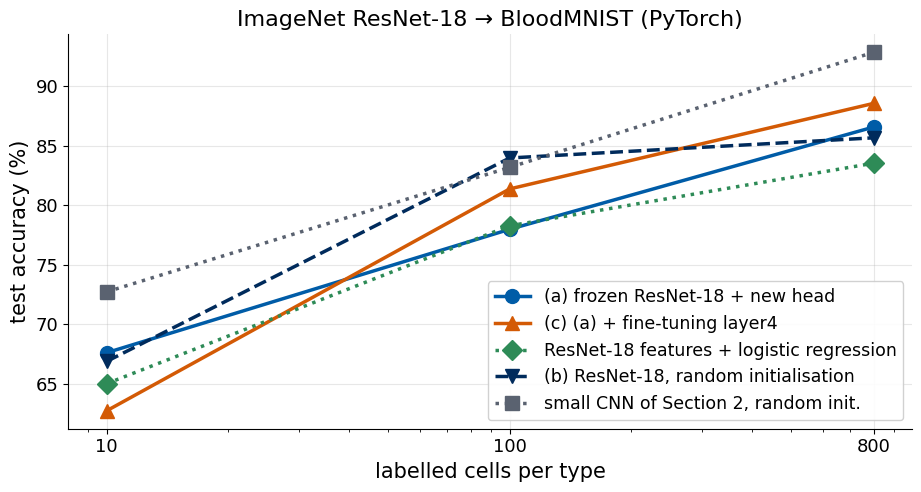

In [38]:
LABELS_B = {"frozen": "(a) frozen ResNet-18 + new head", "layer4": "(c) (a) + fine-tuning layer4",
            "logreg": "ResNet-18 features + logistic regression", "random": "(b) ResNet-18, random initialisation"}
print(f"{'cells per type':>14s} | " + " | ".join(f"{LABELS_B[m]:>40s}" for m in LABELS_B) + " | small CNN, random init.")
for i, n in enumerate(BUDGETS):
    print(f"{n:14d} | " + " | ".join(f"{100 * acc_B[m][i]:33.1f}% ({time_B[m][i]:3.0f} s)" for m in LABELS_B)
          + f" | {100 * acc_A['random'][i]:10.1f}% ({time_A['random'][i]:3.0f} s)")
plot_budget([(LABELS_B["frozen"], acc_B["frozen"], UJBlue, "o", "-"),
             (LABELS_B["layer4"], acc_B["layer4"], DSOrange, "^", "-"),
             (LABELS_B["logreg"], acc_B["logreg"], Green, "D", ":"),
             (LABELS_B["random"], acc_B["random"], UJNavy, "v", "--"),
             ("small CNN of Section 2, random init.", acc_A["random"], UJGray, "s", ":")],
            "ImageNet ResNet-18 → BloodMNIST (PyTorch)", os.path.join(FIGS, "transfer_partB_resnet18.png"))

Two findings stand out. First, logistic regression on frozen ResNet-18 features is the cheapest method by far, a few seconds including the feature extraction, and gives 65.0%, 78.3% and 83.5%, within about three points of the head trained with Adam (67.6%, 78.0%, 86.6%). For a new data set it is the right first experiment. Second, transfer from ImageNet does not beat training from random initialisation on this data set. The small CNN of Section 2, trained on the cells at $32\times32$ pixels, reaches 72.7%, 83.2% and 92.9% and is the best method at 10 and 800 cells per type; the randomly initialised ResNet-18 is best at 100 (84.0%). Fine-tuning `layer4` is the best transfer variant from 100 cells per type on (81.4%, 88.6%). BloodMNIST is a homogeneous data set: centred cells, one staining protocol, one microscope, so a small network learns its few relevant features quickly. Transfer would be expected to help most when the labelled set is smaller and more varied than here, or when the source images are closer to the target, for example a network pretrained on microscopy.

(a) frozen ResNet-18 + new head            recall per type [0.86 0.76 0.74 0.49 0.78 0.81 0.91 0.95]; most frequent error immature granulocyte -> monocyte (121 of 579)


(c) (a) + fine-tuning layer4               recall per type [0.82 0.85 0.78 0.64 0.82 0.79 0.86 0.95]; most frequent error immature granulocyte -> monocyte (89 of 579)
ResNet-18 features + logistic regression   recall per type [0.82 0.81 0.77 0.57 0.79 0.73 0.86 0.92]; most frequent error immature granulocyte -> monocyte (119 of 579)


(b) ResNet-18, random initialisation       recall per type [0.89 0.93 0.85 0.46 0.85 0.81 0.97 0.99]; most frequent error immature granulocyte -> monocyte (129 of 579)


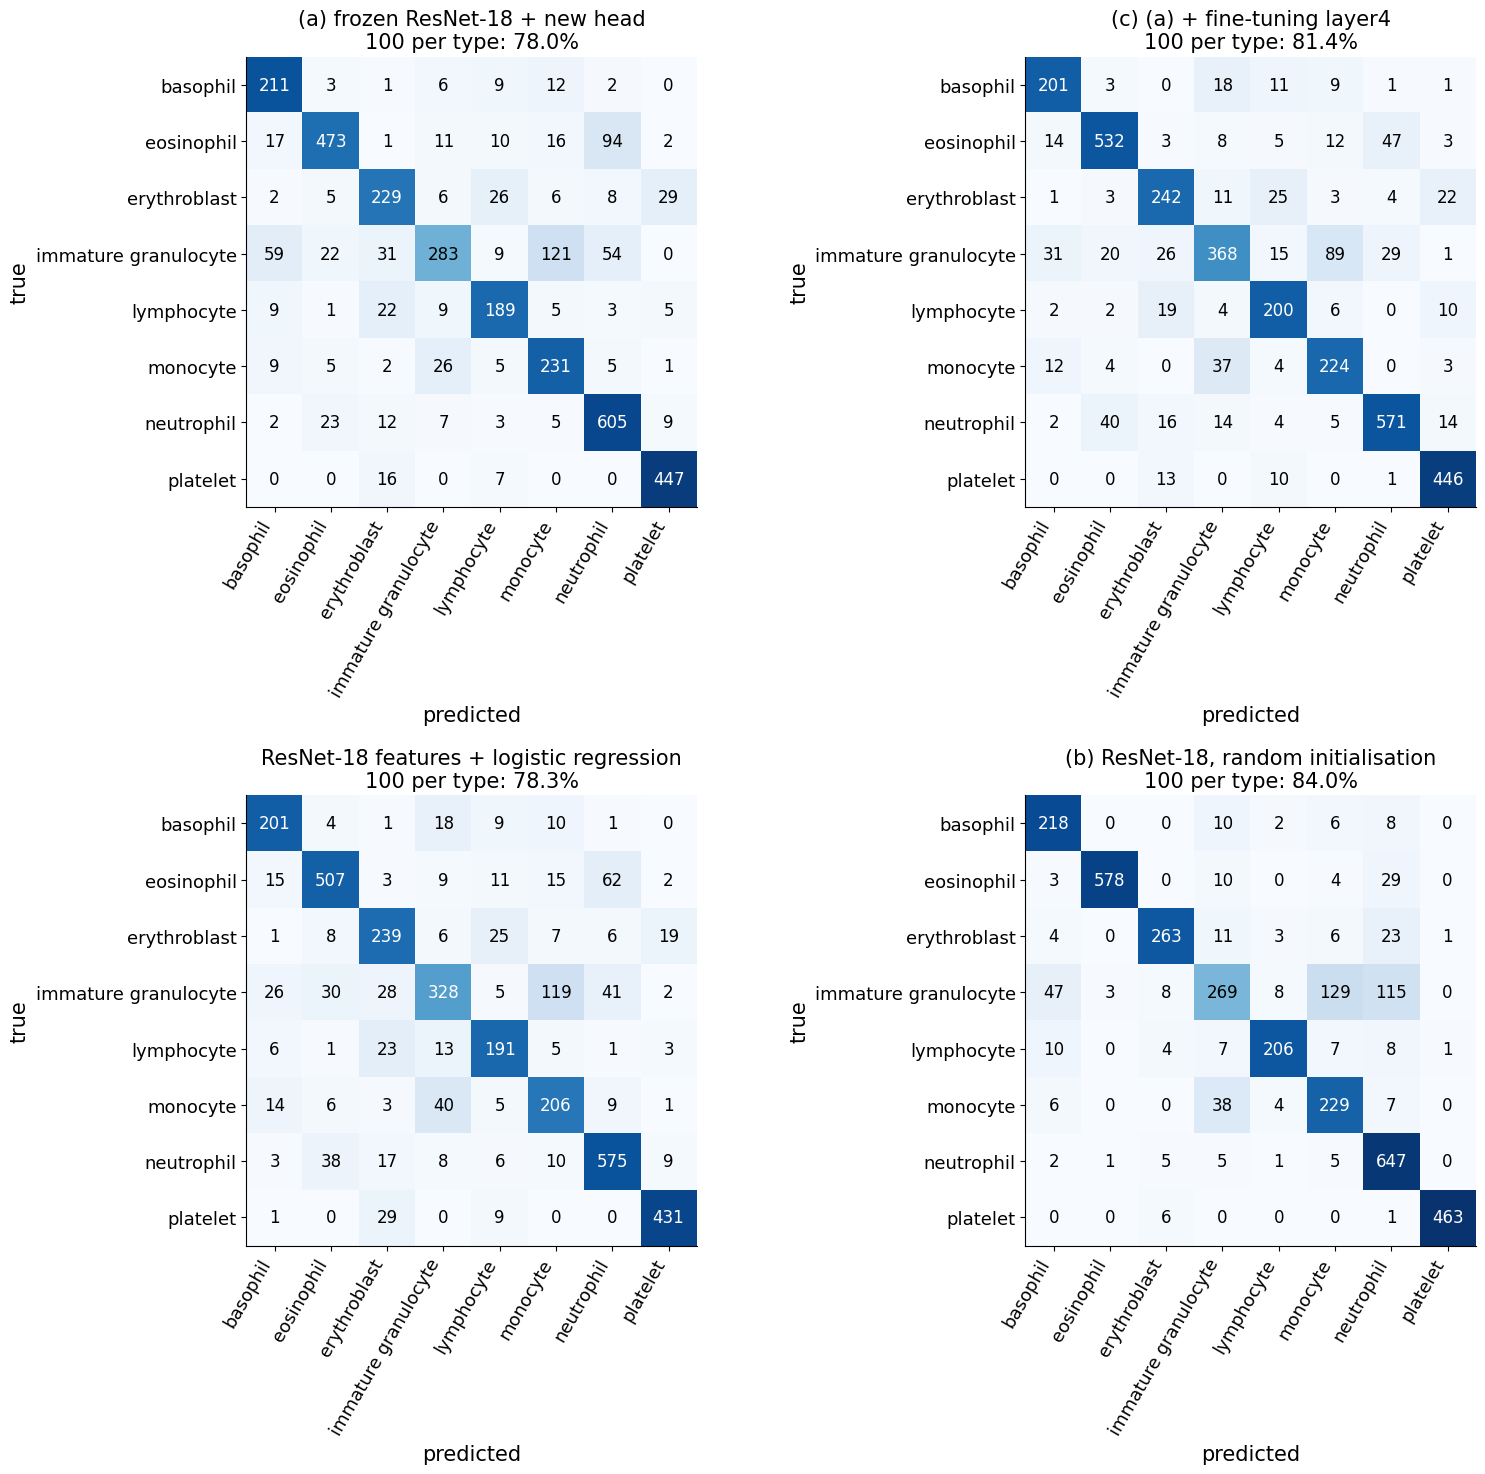

saved results/Lab_014a_resnet18_frozen_100_per_type.pt
saved results/Lab_014a_resnet18_layer4_100_per_type.pt
saved results/Lab_014a_resnet18_random_100_per_type.pt
saved results/Lab_014a_resnet18_features_logreg_100_per_type.npz


In [39]:
fig, axes = plt.subplots(2, 2, figsize=(16, 15))
for ax, m in zip(axes.ravel(), LABELS_B):
    if m == "logreg": pred = models_B[(m, 100)].predict(F_te.numpy())
    elif m == "layer4": pred = predict(Top(models_B[(m, 100)]), H3_te).argmax(1).numpy()
    else: pred = predict(models_B[(m, 100)], X64_te).argmax(1).numpy()
    cm = confusion_matrix(yb_te, pred)
    plot_confusion(ax, cm, BLOOD_TYPES, f"{LABELS_B[m]}\n100 per type: {100 * (pred == yb_te).mean():.1f}%")
    print(f"{LABELS_B[m]:42s} recall per type {np.round(np.diag(cm) / cm.sum(1), 2)}; most frequent error {most_confused(cm)}")
plt.tight_layout(); plt.show()
for m in ["frozen", "layer4", "random"]:
    path = os.path.join(RESULTS, f"Lab_014a_resnet18_{m}_100_per_type.pt")
    torch.save(models_B[(m, 100)].state_dict(), path); print("saved", path)
clf = models_B[("logreg", 100)]
path = os.path.join(RESULTS, "Lab_014a_resnet18_features_logreg_100_per_type.npz")
np.savez(path, coef=clf[-1].coef_, intercept=clf[-1].intercept_, mean=clf[0].mean_, scale=clf[0].scale_); print("saved", path)

All four ResNet-18 models make the same main error, immature granulocytes predicted as monocytes (89 to 129 of 579), as the CIFAR-10 models of Section 2 did. The random-initialisation network has the highest recall on neutrophils (0.97) and eosinophils (0.93) but the lowest on immature granulocytes (0.46); fine-tuning `layer4` gives the most even recall, between 0.64 and 0.95. The hard pair is the same for every network and every training regime, which points to the data (similar morphology, small images) rather than to the method.

## 4. A pretrained ResNet-18 on satellite images

On blood cells, neither our CIFAR-10 network nor the ImageNet ResNet-18 beat a small CNN trained from random initialisation. The same recipe is now applied to a target that resembles the source much more closely: small colour images of European landscapes taken from orbit, with ten classes defined by textures and colours (fields, forest, water, roads, houses) of the kind that fill ImageNet photographs.

### Satellite images (EuroSAT)

EuroSAT (P. Helber, B. Bischke, A. Dengel, D. Borth, *EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification*, IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing 12, 2217–2226 (2019), [doi:10.1109/JSTARS.2019.2918242](https://doi.org/10.1109/JSTARS.2019.2918242)) consists of 27 000 image patches from the Sentinel-2 satellites of the European Copernicus programme, covering 34 European countries. One sample is a $64\times64$ pixel patch; at the 10 m ground resolution of the visible bands it shows a square of 640 m by 640 m. The satellites record 13 spectral bands; the RGB version used here keeps the red, green and blue bands (Sentinel-2 bands B04, B03, B02) as an 8-bit colour JPEG image, three integers from 0 to 255 per pixel. The data are distributed under the MIT licence on [Zenodo](https://zenodo.org/records/7711810) and on the [authors' page](https://github.com/phelber/EuroSAT); the Sentinel data themselves are free under the Copernicus terms. The notebook uses the RGB version and downloads it once (95 MB) from Zenodo.

| class | images | what the patch shows |
|---|---|---|
| AnnualCrop | 3000 | arable fields sown every year |
| Forest | 3000 | closed tree cover |
| HerbaceousVegetation | 3000 | grassland and shrubs, not grazed |
| Highway | 2500 | a motorway or major road crossing the patch |
| Industrial | 2500 | industrial buildings and yards |
| Pasture | 2000 | grazed meadows |
| PermanentCrop | 2500 | orchards and vineyards |
| Residential | 3000 | houses and streets |
| River | 2500 | a river crossing the patch |
| SeaLake | 3000 | open water |

For each class we fix one random order of its images (seed 0). The first 200 images of every class form the test set, 2000 images in total, and the next 1000 form a pool from which the labelled training images are drawn: 10, 100 or 1000 per class. Only these 12 000 images are decoded.

In [40]:
EURO_GRID_PATH = os.path.join(FIGS, "transfer_eurosat_examples.png")   # example grid for the slides
BEAMER_FIGS = True

import zipfile, io
from PIL import Image

EUROSAT_URL = "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1"

def eurosat_zip():
    # the RGB archive: local copy first, otherwise the Zenodo record of the authors (95 MB)
    for name in ["EuroSAT.zip", "EuroSAT_RGB.zip"]:
        if os.path.exists(os.path.join(DATA, name)): return os.path.join(DATA, name)
    path = os.path.join(DATA, "EuroSAT_RGB.zip"); print("downloading EuroSAT RGB ...")
    urllib.request.urlretrieve(EUROSAT_URL, path)
    return path

zf = zipfile.ZipFile(eurosat_zip())
files = sorted(n for n in zf.namelist() if n.lower().endswith(".jpg"))
EURO_CLASSES = sorted({n.split("/")[-2] for n in files})                     # class = name of the parent folder
by_class = [[n for n in files if n.split("/")[-2] == c] for c in EURO_CLASSES]
N_TEST_EU, N_POOL_EU = 200, 1000
r = np.random.default_rng(0)
order = [r.permutation(len(f)) for f in by_class]
te_files = [by_class[c][i] for c in range(10) for i in order[c][:N_TEST_EU]]
pool_files = [by_class[c][i] for c in range(10) for i in order[c][N_TEST_EU:N_TEST_EU + N_POOL_EU]]
read = lambda names: np.stack([np.asarray(Image.open(io.BytesIO(zf.read(n))).convert("RGB")) for n in names])
t0 = time.time()
Xe_te_raw, ye_te = read(te_files), np.repeat(np.arange(10), N_TEST_EU)        # (2000, 64, 64, 3) uint8
Xe_pool_raw, ye_pool = read(pool_files), np.repeat(np.arange(10), N_POOL_EU)  # (10000, 64, 64, 3) uint8
assert Xe_te_raw.shape == (2000, 64, 64, 3) and Xe_pool_raw.shape == (10000, 64, 64, 3)
print(f"{len(files)} images in the archive, decoded {len(te_files) + len(pool_files)} in {time.time() - t0:.1f} s")
print(f"{'class':22s} {'images':>7s}")
for c, f in zip(EURO_CLASSES, by_class): print(f"{c:22s} {len(f):7d}")

27000 images in the archive, decoded 12000 in 2.4 s
class                   images
AnnualCrop                3000
Forest                    3000
HerbaceousVegetation      3000
Highway                   2500
Industrial                2500
Pasture                   2000
PermanentCrop             2500
Residential               3000
River                     2500
SeaLake                   3000


saved figures/transfer_eurosat_examples.png


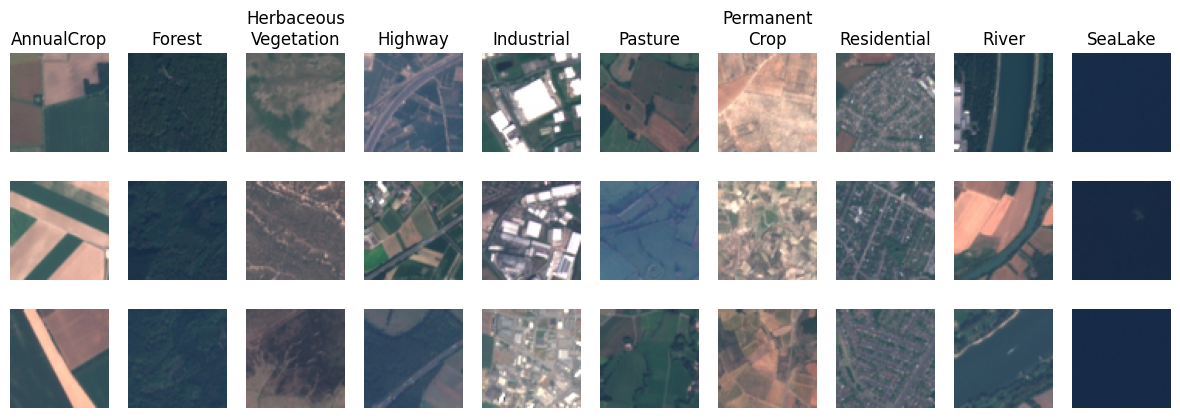

In [41]:
with plt.rc_context({"font.size": 13}):
    fig, axes = plt.subplots(3, 10, figsize=(12, 4.6))
    for c in range(10):
        for k in range(3):
            axes[k, c].imshow(Xe_pool_raw[c * N_POOL_EU + k]); axes[k, c].axis("off")
        axes[0, c].set_title({"HerbaceousVegetation": "Herbaceous\nVegetation", "PermanentCrop": "Permanent\nCrop"}.get(EURO_CLASSES[c], EURO_CLASSES[c]), fontsize=12)
    fig.tight_layout()
    if EURO_GRID_PATH: fig.savefig(EURO_GRID_PATH, dpi=150); print("saved", EURO_GRID_PATH)
    plt.show()

With 10 and 100 labelled images per class the result depends on which images happen to be labelled, so the cheap methods are repeated for three random draws (seeds 0, 1, 2) and reported as mean and standard deviation over the $S$ seeds,
$$\bar a=\frac1S\sum_{s=1}^{S}a_s,\qquad \sigma_a=\Big(\frac1{S-1}\sum_{s=1}^{S}(a_s-\bar a)^2\Big)^{1/2}, \tag{7}$$
where $a_s$ is the test accuracy for seed $s$. With 1000 per class the whole pool is labelled and there is one run.

In [42]:
BUDGETS_EU, SEEDS_EU = [10, 100, 1000], [0, 1, 2]
RAND_BUDGETS_EU = BUDGETS_EU                    # budgets for the randomly initialised ResNet-18

def euro_subset(n, seed):
    # positions in the pool of n labelled images per class (all 1000 when n = 1000)
    r = np.random.default_rng(100 + seed)
    return np.concatenate([c * N_POOL_EU + (np.arange(N_POOL_EU) if n == N_POOL_EU else r.choice(N_POOL_EU, n, replace=False))
                           for c in range(10)])

seeds_for = lambda n: SEEDS_EU if n < N_POOL_EU else [0]
assert all(np.array_equal(np.bincount(ye_pool[euro_subset(n, s)]), [n] * 10) for n in BUDGETS_EU for s in seeds_for(n))
Xe_pool, Xe_te = blood_as_imagenet(Xe_pool_raw), blood_as_imagenet(Xe_te_raw)    # the same ImageNet standardisation, equation (4)
print("EuroSAT pool", tuple(Xe_pool.shape), " test", tuple(Xe_te.shape))

EuroSAT pool (10000, 3, 64, 64)  test (2000, 3, 64, 64)


### Frozen ImageNet features and logistic regression

The frozen ResNet-18 turns every patch into 512 features, at the native 64 pixels and after bilinear enlargement to 128 pixels; the `layer3` outputs at 64 pixels are stored as well, for fine-tuning. A logistic regression on standardised features, as in Section 3, is then fitted for every budget and seed.

In [43]:
t0 = time.time(); H3e_pool, Fe_pool = trunk_and_features(resnet, Xe_pool); H3e_te, Fe_te = trunk_and_features(resnet, Xe_te)
t64 = time.time() - t0
t0 = time.time(); _, Fe_pool128 = trunk_and_features(resnet, Xe_pool, size=128, keep_h3=False)
_, Fe_te128 = trunk_and_features(resnet, Xe_te, size=128, keep_h3=False); t128 = time.time() - t0
n_img = len(Xe_pool) + len(Xe_te)
print(f"features of {n_img} images: 64 px {t64:.1f} s ({1000 * t64 / n_img:.1f} ms per image), 128 px {t128:.1f} s ({1000 * t128 / n_img:.1f} ms per image)")

ACC_EU = {}                                                                 # (method, n) -> list of test accuracies over seeds
TIME_EU = {}
def record(method, n, acc, t):
    ACC_EU.setdefault((method, n), []).append(acc); TIME_EU.setdefault((method, n), []).append(t)

LR_EU = {}
for n in BUDGETS_EU:
    for s in seeds_for(n):
        idx = euro_subset(n, s)
        for res, (Ftr, Fte) in {"64": (Fe_pool, Fe_te), "128": (Fe_pool128, Fe_te128)}.items():
            clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
            t0 = time.time(); clf.fit(Ftr[idx].numpy(), ye_pool[idx]); t = time.time() - t0
            record(f"logreg{res}", n, clf.score(Fte.numpy(), ye_te), t)
            if s == 0: LR_EU[(res, n)] = clf
    print(f"n = {n:4d} per class: logistic regression 64 px {100 * np.mean(ACC_EU[('logreg64', n)]):.1f}%,"
          f" 128 px {100 * np.mean(ACC_EU[('logreg128', n)]):.1f}%  ({len(seeds_for(n))} seed(s))")

features of 12000 images: 64 px 11.5 s (1.0 ms per image), 128 px 44.5 s (3.7 ms per image)


n =   10 per class: logistic regression 64 px 76.7%, 128 px 77.2%  (3 seed(s))


n =  100 per class: logistic regression 64 px 86.9%, 128 px 88.4%  (3 seed(s))


n = 1000 per class: logistic regression 64 px 89.1%, 128 px 91.3%  (1 seed(s))


The frozen ImageNet features separate the land-use classes well from very few labels: logistic regression reaches 76.7% with 10 images per class (mean over three seeds, standard deviation 1.2), 86.9% with 100 and 89.1% with 1000 at 64 pixels. Enlarging the patches to 128 pixels adds 0.5 to 2.2 points (77.2%, 88.4%, 91.3%) at 3.7 instead of 1.0 ms per image. The step from 10 to 100 labels is worth ten points, the step from 100 to 1000 only two to three.

### New head and fine-tuning on EuroSAT

The surgery is the one of Section 3 with a new output layer of 10 classes instead of 8. The new layer is trained with Adam on the stored features of the 64-pixel patches (50 epochs, at least 500 steps); then `layer4` is unfrozen and trained together with it on the stored `layer3` outputs (5 epochs, at least 200 steps, learning rate $10^{-4}$), for seed 0. The diagrams and the stage table are read from the model as before.

per stage, frozen network with new output layer (64×64 input)
stage           output shape  parameters  trainable
stem                16×16×64       9,536  no
layer1              16×16×64     147,968  no
layer2               8×8×128     525,568  no
layer3               4×4×256   2,099,712  no
layer4               2×2×512   8,393,728  no
fc                        10       5,130  yes
total                         11,181,642
trainable                          5,130
frozen                        11,176,512



saved results/Lab_014a_arch_eurosat_frozen.png


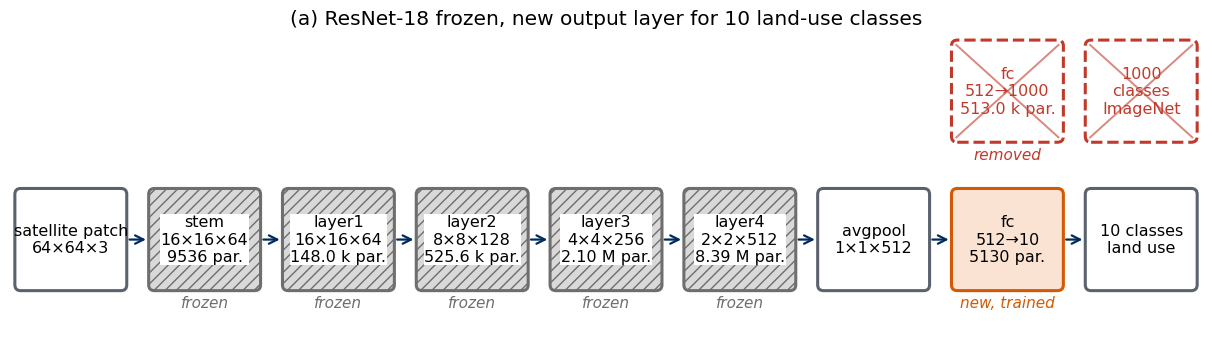

per stage, fine-tuning (c)
stage           output shape  parameters  trainable
stem                16×16×64       9,536  no
layer1              16×16×64     147,968  no
layer2               8×8×128     525,568  no
layer3               4×4×256   2,099,712  no
layer4               2×2×512   8,393,728  yes
fc                        10       5,130  yes
total                         11,181,642
trainable                      8,398,858
frozen                         2,782,784



saved results/Lab_014a_arch_eurosat_finetune.png


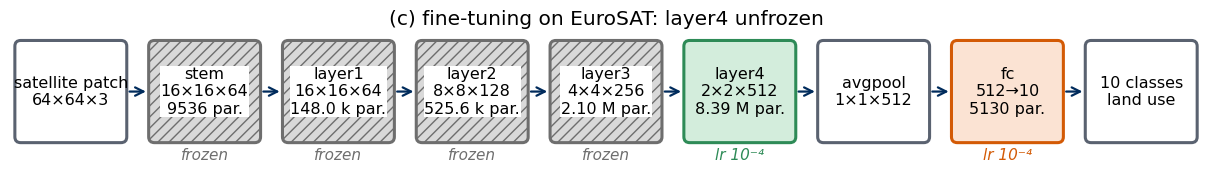

In [44]:
torch.manual_seed(0)
m_eu = copy.deepcopy(resnet); m_eu.fc = nn.Linear(512, len(EURO_CLASSES)); set_trainable(m_eu, False); set_trainable(m_eu.fc, True)
EU_STAGES = [(s, SH[64][o], mods) for s, mods, o in STAGE_MODS] + [("fc", hook_shapes(m_eu, torch.zeros(1, 3, 64, 64), ["fc"])["fc"], ["fc"])]
stage_table(m_eu, EU_STAGES, "per stage, frozen network with new output layer (64×64 input)")
euro_out = lambda m, tag=None: [dict(name="avgpool", detail=SH[64]["avgpool"], status="data"), fc_box(m, "new", tag),
                                dict(name=f"{m.fc.out_features} classes", detail="land use", status="data")]
total = draw_blocks([dict(name="satellite patch", detail="64×64×3", status="data")] + resnet_blocks(m_eu, lambda s: "frozen", lambda s: "frozen")
                    + euro_out(m_eu) + [fc_box(resnet, "removed", "removed", row=1, at=7),
                                        dict(name=f"{resnet.fc.out_features}\nclasses", detail="ImageNet", status="removed", row=1, at=8, tag="")],
                    "(a) ResNet-18 frozen, new output layer for 10 land-use classes", os.path.join(RESULTS, "Lab_014a_arch_eurosat_frozen.png"))
assert total == count_params(m_eu)
m_tmp = copy.deepcopy(m_eu); set_trainable(m_tmp.layer4, True)
stage_table(m_tmp, EU_STAGES, "per stage, fine-tuning (c)")
total = draw_blocks([dict(name="satellite patch", detail="64×64×3", status="data")]
                    + resnet_blocks(m_tmp, lambda s: "unfrozen" if s == "layer4" else "frozen", lambda s: "lr 10⁻⁴" if s == "layer4" else "frozen")
                    + euro_out(m_tmp, "lr 10⁻⁴"), "(c) fine-tuning on EuroSAT: layer4 unfrozen", os.path.join(RESULTS, "Lab_014a_arch_eurosat_finetune.png"))
assert total == count_params(m_tmp)

In [45]:
ye_pool_t, ye_te_t = torch.from_numpy(ye_pool).long(), torch.from_numpy(ye_te).long()
MODELS_EU = {}
for n in BUDGETS_EU:
    idx = euro_subset(n, 0)
    m = copy.deepcopy(m_eu)
    S = max(MIN_STEPS_HEAD, int(np.ceil(EPOCHS_HEAD * 10 * n / 64)))
    t_a, l_a = train_steps(m.fc, m.fc.parameters(), 1e-3, Fe_pool[idx], ye_pool_t[idx], S)
    record("head", n, accuracy(m.fc, Fe_te, ye_te_t), t_a)
    set_trainable(m.layer4, True)
    S4 = max(MIN_STEPS_FT, int(np.ceil(EPOCHS_FT * 10 * n / 64)))
    t_c, l_c = train_steps(Top(m), list(m.layer4.parameters()) + list(m.fc.parameters()), 1e-4, H3e_pool[idx], ye_pool_t[idx], S4, seed=1)
    record("layer4", n, accuracy(Top(m), H3e_te, ye_te_t), t_a + t_c); MODELS_EU[("layer4", n)] = m
    print(f"n = {n:4d}: new head {S} steps, loss {l_a:.3f}, test {100 * ACC_EU[('head', n)][0]:.1f}% | "
          f"layer4 {S4} steps in {t_c:.0f} s, loss {l_c:.3f}, test {100 * ACC_EU[('layer4', n)][0]:.1f}%")

n =   10: new head 500 steps, loss 0.007, test 76.8% | layer4 200 steps in 14 s, loss 0.000, test 73.2%


n =  100: new head 782 steps, loss 0.035, test 86.8% | layer4 200 steps in 13 s, loss 0.003, test 87.1%


n = 1000: new head 7813 steps, loss 0.064, test 90.0% | layer4 782 steps in 54 s, loss 0.045, test 93.7%


The output layer trained with Adam on the stored features gives the same accuracy as logistic regression (76.8%, 86.8%, 90.0%), as it should for the same model. Fine-tuning `layer4` again depends on the number of labels: with 10 per class it overfits (training loss 0.000) and falls to 73.2%, with 100 it is level (87.1%), and with 1000 per class it is the best method of the notebook on this data set, 93.7%.

### References trained from random initialisation

Two networks start from random weights: the same ResNet-18, trained on the 64-pixel patches with Adam (learning rate $10^{-3}$, 3 epochs and at least 300 steps, seed 0), and the small CNN architecture of Section 2 with new layers for 10 classes, trained on the patches reduced to $32\times32$ pixels by averaging $2\times2$ blocks and standardised with the means and standard deviations of the pool (twice 20 epochs and at least 600 steps, three seeds for 10 and 100 per class).

In [46]:
for n in RAND_BUDGETS_EU:
    idx = euro_subset(n, 0)
    S = max(MIN_STEPS_RAND, int(np.ceil(EPOCHS_RAND * 10 * n / 64)))
    torch.manual_seed(0)
    mr = torchvision.models.resnet18(weights=None, num_classes=10)
    t, loss = train_steps(mr, mr.parameters(), 1e-3, Xe_pool[idx], ye_pool_t[idx], S)
    record("resnet_random", n, accuracy(mr, Xe_te, ye_te_t), t); MODELS_EU[("resnet_random", n)] = mr
    print(f"n = {n:4d}: ResNet-18 random init., {S} steps in {t:.0f} s, loss {loss:.3f}, test {100 * ACC_EU[('resnet_random', n)][0]:.1f}%")

X32_pool = F.avg_pool2d(torch.from_numpy(Xe_pool_raw).permute(0, 3, 1, 2).float() / 255, 2)    # (10000, 3, 32, 32)
X32_te = F.avg_pool2d(torch.from_numpy(Xe_te_raw).permute(0, 3, 1, 2).float() / 255, 2)
mu32, sd32 = X32_pool.mean((0, 2, 3), keepdim=True), X32_pool.std((0, 2, 3), keepdim=True)
X32_pool, X32_te = (X32_pool - mu32) / sd32, (X32_te - mu32) / sd32
for n in BUDGETS_EU:
    for s in seeds_for(n):
        idx = euro_subset(n, s)
        S = 2 * max(MIN_STEPS_A, int(np.ceil(EPOCHS_A * 10 * n / 64)))
        torch.manual_seed(s)
        mc = TransferNet(CifarCNN(regularise=True).body, n_classes=10)
        t, loss = train_steps(mc, mc.parameters(), 1e-3, X32_pool[idx], ye_pool_t[idx], S, seed=s)
        record("small_cnn", n, accuracy(mc, X32_te, ye_te_t), t)
        if s == 0: MODELS_EU[("small_cnn", n)] = mc
    print(f"n = {n:4d}: small CNN random init., {S} steps, test {100 * np.mean(ACC_EU[('small_cnn', n)]):.1f}%"
          f" ± {100 * np.std(ACC_EU[('small_cnn', n)], ddof=1) if len(ACC_EU[('small_cnn', n)]) > 1 else 0:.1f}")

n =   10: ResNet-18 random init., 300 steps in 60 s, loss 0.059, test 37.3%


n =  100: ResNet-18 random init., 300 steps in 60 s, loss 0.185, test 63.5%


n = 1000: ResNet-18 random init., 469 steps in 109 s, loss 0.612, test 69.8%


n =   10: small CNN random init., 600 steps, test 54.9% ± 2.3


n =  100: small CNN random init., 626 steps, test 78.0% ± 0.6


n = 1000: small CNN random init., 6250 steps, test 91.9% ± 0.0


Without pretrained weights the picture changes completely. ResNet-18 from random initialisation reaches only 37.3%, 63.5% and 69.8%, with 300 to 469 steps that already take 60 to 109 s; 11 million parameters cannot be fitted from a few hundred images in this budget. The small CNN does better, 54.9 ± 2.3%, 78.0 ± 0.6% and 91.9%, but needs about 1000 labelled images per class to catch up with the frozen features, which reach 77% with 10.

### Comparison on EuroSAT

The table lists the mean test accuracy over the seeds of equation (7), with the standard deviation where there are three seeds, and the training time of the first seed (for logistic regression the fit only; the features are extracted once for all methods).

method                                                  10               100              1000
features 64 px + logistic regression       76.7 ± 1.2 (  0 s)   86.9 ± 0.6 (  1 s)   89.1 ± 0.0 (  2 s)
features 128 px + logistic regression      77.2 ± 1.4 (  0 s)   88.4 ± 0.7 (  1 s)   91.3 ± 0.0 (  2 s)
(a) frozen ResNet-18 + new fc              76.8 ± 0.0 (  0 s)   86.8 ± 0.0 (  0 s)   90.0 ± 0.0 (  4 s)
(c) (a) + fine-tuning layer4               73.2 ± 0.0 ( 14 s)   87.1 ± 0.0 ( 14 s)   93.7 ± 0.0 ( 57 s)
(b) ResNet-18, random initialisation       37.3 ± 0.0 ( 60 s)   63.5 ± 0.0 ( 60 s)   69.8 ± 0.0 (109 s)
small CNN, random initialisation           54.9 ± 2.3 ( 17 s)   78.0 ± 0.6 ( 17 s)   91.9 ± 0.0 (388 s)


saved figures/transfer_partC_eurosat.png


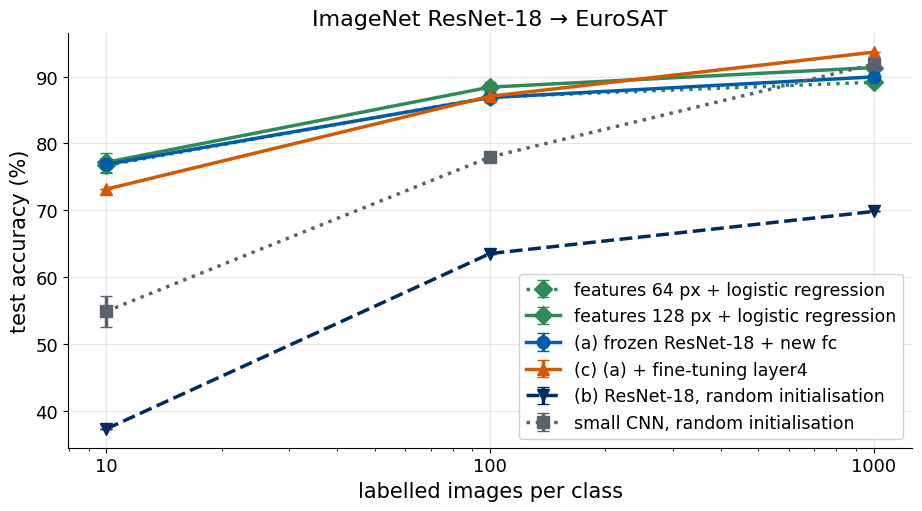

In [47]:
LABELS_EU = {"logreg64": "features 64 px + logistic regression", "logreg128": "features 128 px + logistic regression",
             "head": "(a) frozen ResNet-18 + new fc", "layer4": "(c) (a) + fine-tuning layer4",
             "resnet_random": "(b) ResNet-18, random initialisation", "small_cnn": "small CNN, random initialisation"}
def mean_std(m, n):
    # mean and standard deviation over seeds, equation (7); NaN when the run was not done
    if (m, n) not in ACC_EU: return np.nan, 0.0
    a = 100 * np.array(ACC_EU[(m, n)]); return a.mean(), (a.std(ddof=1) if len(a) > 1 else 0.0)
print(f"{'method':40s} " + " ".join(f"{n:>17d}" for n in BUDGETS_EU))
for m, lab in LABELS_EU.items():
    print(f"{lab:40s} " + " ".join(f"{mean_std(m, n)[0]:6.1f} ± {mean_std(m, n)[1]:3.1f} ({TIME_EU.get((m, n), [np.nan])[0]:3.0f} s)" for n in BUDGETS_EU))

STY = {"logreg64": (Green, "D", ":"), "logreg128": (Green, "D", "-"), "head": (UJBlue, "o", "-"), "layer4": (DSOrange, "^", "-"),
       "resnet_random": (UJNavy, "v", "--"), "small_cnn": (UJGray, "s", ":")}
def budget_panel(ax, budgets, curves, title):
    # curves: list of (label, means, stds, (colour, marker, linestyle))
    for lab, mu, sd, (c, mk, ls) in curves:
        ax.errorbar(budgets, mu, yerr=sd, marker=mk, ls=ls, color=c, lw=2.5, ms=9, capsize=4, label=lab)
    ax.set_xscale("log"); ax.set_xticks(budgets); ax.set_xticklabels([str(b) for b in budgets])
    ax.set_ylabel("test accuracy (%)"); ax.set_title(title); ax.grid(alpha=0.3)

with plt.rc_context({"font.size": 16, "legend.fontsize": 12.5}):
    fig, ax = plt.subplots(figsize=(9.5, 5.4))
    budget_panel(ax, BUDGETS_EU, [(LABELS_EU[m], [mean_std(m, n)[0] for n in BUDGETS_EU], [mean_std(m, n)[1] for n in BUDGETS_EU], STY[m])
                                  for m in LABELS_EU], "ImageNet ResNet-18 → EuroSAT")
    ax.set_xlabel("labelled images per class"); ax.legend(loc="lower right", framealpha=0.9)
    fig.tight_layout()
    if BEAMER_FIGS: fig.savefig(os.path.join(FIGS, "transfer_partC_eurosat.png"), dpi=200); print("saved", os.path.join(FIGS, "transfer_partC_eurosat.png"))
    plt.show()

On EuroSAT, transfer learning pays off clearly. With 10 labelled images per class, frozen ImageNet features with logistic regression (76.7%, or 77.2% at 128 pixels) beat the small CNN trained from random initialisation by 22 points and the randomly initialised ResNet-18 by almost 40; with 100 per class the gap to the small CNN is still 9 to 10 points (86.9–88.4% against 78.0%). With 1000 per class the small CNN (91.9%) catches up with the frozen features (89.1–91.3%), and only fine-tuning `layer4` stays ahead (93.7%). The cheapest method, a logistic regression fitted in about a second on features extracted once, is also the best one at small label budgets.

saved figures/transfer_blood_vs_eurosat.png


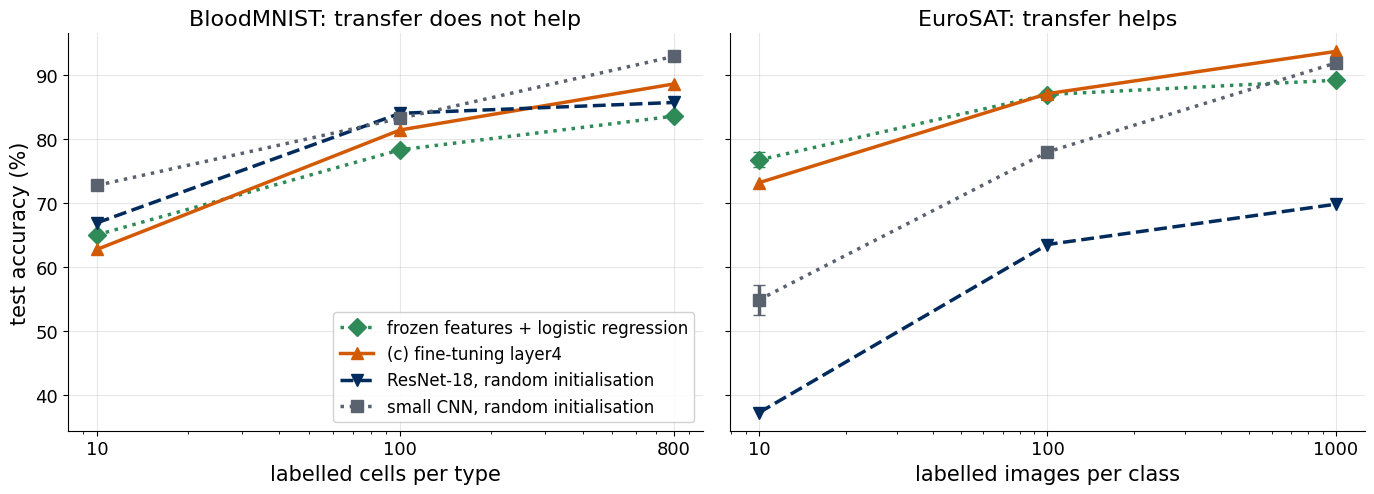

In [48]:
with plt.rc_context({"font.size": 15, "legend.fontsize": 12}):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
    budget_panel(axes[0], BUDGETS, [("frozen features + logistic regression", 100 * np.array(acc_B["logreg"]), None, STY["logreg64"]),
                                    ("(c) fine-tuning layer4", 100 * np.array(acc_B["layer4"]), None, STY["layer4"]),
                                    ("ResNet-18, random initialisation", 100 * np.array(acc_B["random"]), None, STY["resnet_random"]),
                                    ("small CNN, random initialisation", 100 * np.array(acc_A["random"]), None, STY["small_cnn"])],
                 "BloodMNIST: transfer does not help")
    budget_panel(axes[1], BUDGETS_EU, [("frozen features + logistic regression", [mean_std("logreg64", n)[0] for n in BUDGETS_EU],
                                        [mean_std("logreg64", n)[1] for n in BUDGETS_EU], STY["logreg64"]),
                                       ("(c) fine-tuning layer4", [mean_std("layer4", n)[0] for n in BUDGETS_EU], None, STY["layer4"]),
                                       ("ResNet-18, random initialisation", [mean_std("resnet_random", n)[0] for n in BUDGETS_EU], None, STY["resnet_random"]),
                                       ("small CNN, random initialisation", [mean_std("small_cnn", n)[0] for n in BUDGETS_EU],
                                        [mean_std("small_cnn", n)[1] for n in BUDGETS_EU], STY["small_cnn"])],
                 "EuroSAT: transfer helps")
    axes[0].set_xlabel("labelled cells per type"); axes[1].set_xlabel("labelled images per class"); axes[1].set_ylabel("")
    axes[0].legend(loc="lower right", framealpha=0.9)
    fig.tight_layout()
    if BEAMER_FIGS: fig.savefig(os.path.join(FIGS, "transfer_blood_vs_eurosat.png"), dpi=200); print("saved", os.path.join(FIGS, "transfer_blood_vs_eurosat.png"))
    plt.show()

The two panels show the same network with the same recipe on two targets, and opposite conclusions. Three differences between the targets explain them. The first is the distance between source and target images: EuroSAT patches are natural-colour photographs of fields, forest, water, roads and roofs, the textures and colours that ImageNet photographs are full of, whereas blood smears are stained cells with colour statistics far from ImageNet (Section 3: the unchanged network calls most cells "golf ball"). The second is the variability of the target: BloodMNIST cells are centred, of similar size, recorded with one microscope and one staining protocol, so a small CNN learns the few features that separate the types from 80 labelled images (72.7%); EuroSAT patches vary in season, illumination, region and scale, and ten examples per class do not cover this variety unless the features already encode it. The third is the label budget: the advantage of pretrained features is largest at 10 and 100 labels per class and shrinks at 1000, where training from random initialisation has enough data. Transfer from a large pretrained network should therefore be the first experiment when labels are scarce and the target images look like natural photographs, and it should always be compared with a small network trained from random initialisation, which on homogeneous scientific images can win.

### Confusion matrices on EuroSAT

The four models trained on 100 images per class (seed 0): logistic regression on the 128-pixel features, the fine-tuned network, and the two references from random initialisation.

features 128 px + logistic regression    most frequent error River -> Highway (20 of 200)
(c) (a) + fine-tuning layer4             most frequent error River -> Highway (24 of 200)


(b) ResNet-18, random initialisation     most frequent error PermanentCrop -> HerbaceousVegetation (54 of 200)
small CNN, random initialisation         most frequent error Highway -> River (39 of 200)


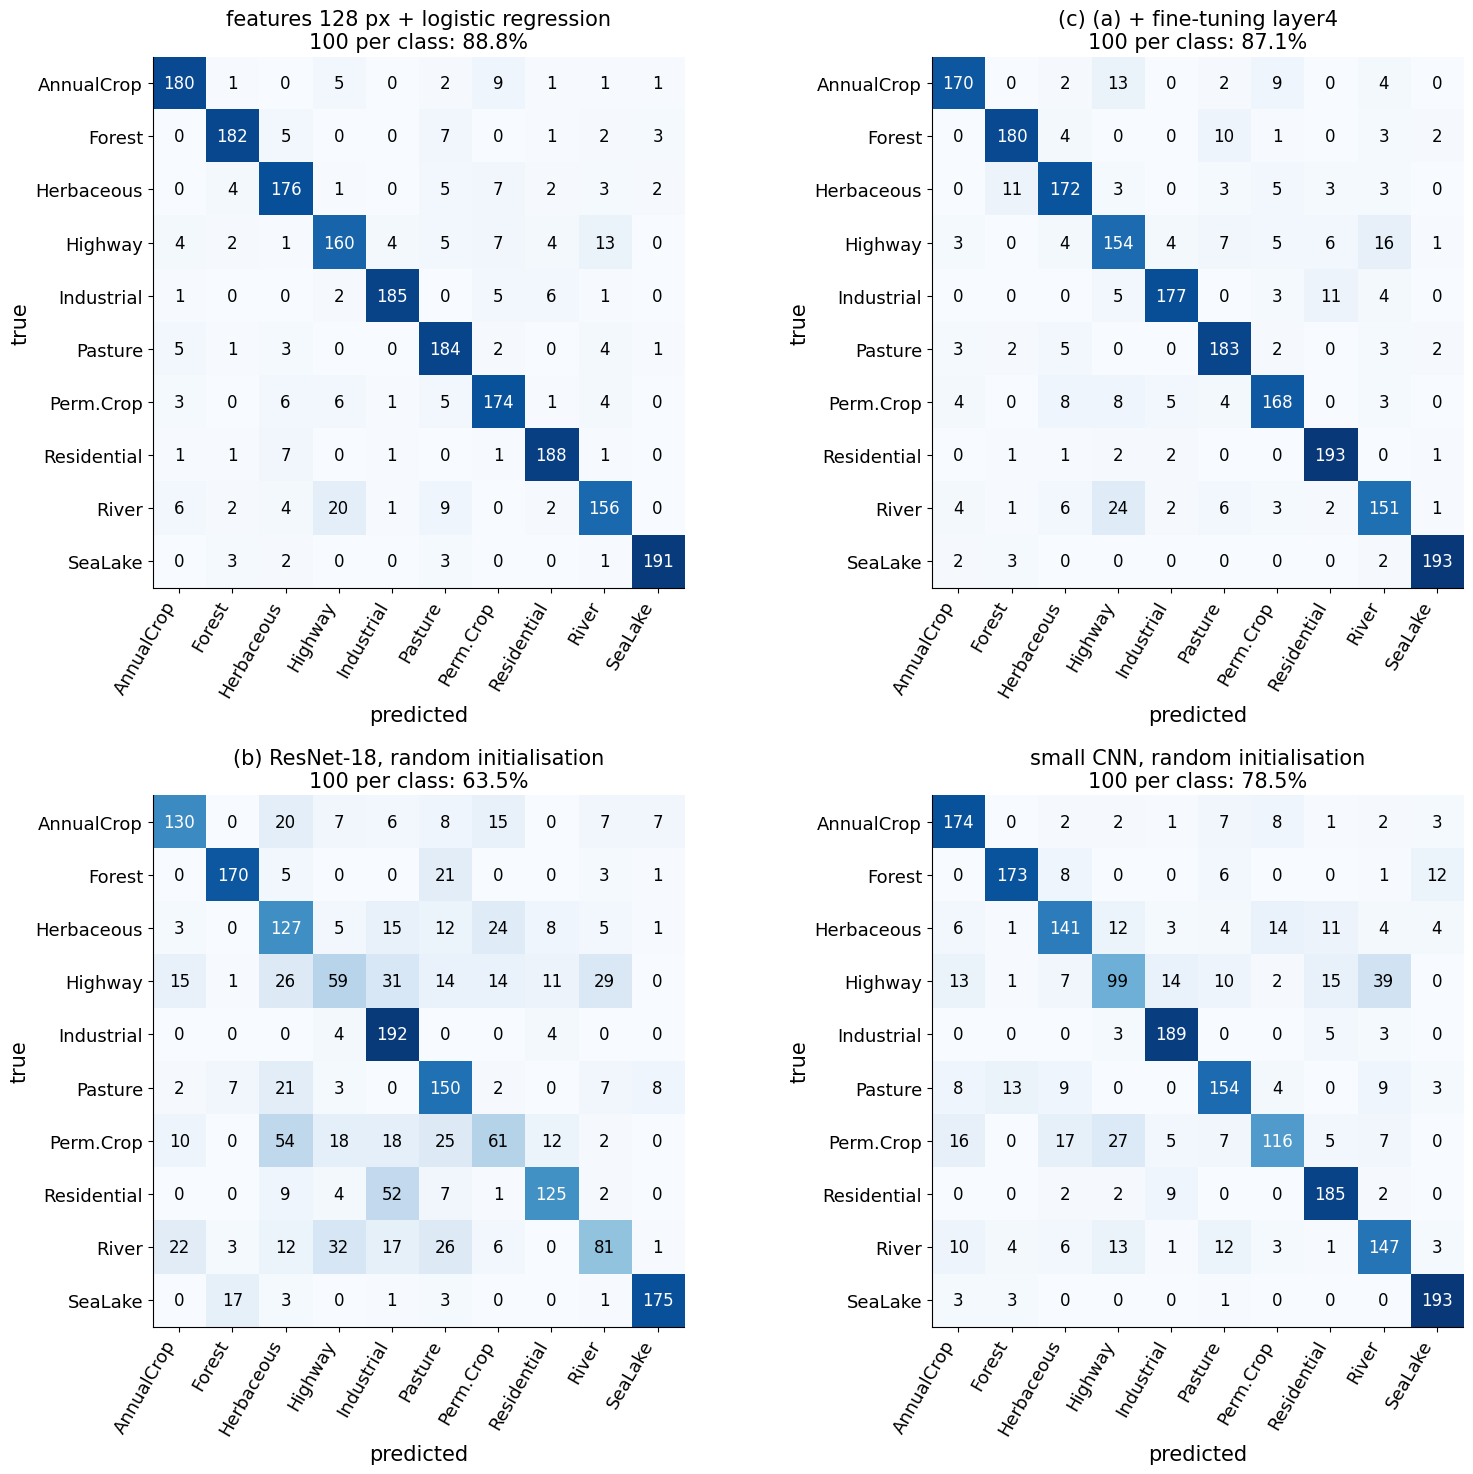

saved results/Lab_014a_eurosat_layer4_100_per_class.pt


saved results/Lab_014a_eurosat_resnet_random_100_per_class.pt
saved results/Lab_014a_eurosat_small_cnn_100_per_class.pt
saved results/Lab_014a_eurosat_logreg128_100_per_class.npz


In [49]:
EU_SHORT = [{"HerbaceousVegetation": "Herbaceous", "PermanentCrop": "Perm.Crop"}.get(c, c) for c in EURO_CLASSES]
idx100 = euro_subset(100, 0)
preds = {"logreg128": LR_EU[("128", 100)].predict(Fe_te128.numpy()),
         "layer4": predict(Top(MODELS_EU[("layer4", 100)]), H3e_te).argmax(1).numpy(),
         "resnet_random": predict(MODELS_EU[("resnet_random", 100)], Xe_te).argmax(1).numpy(),
         "small_cnn": predict(MODELS_EU[("small_cnn", 100)], X32_te).argmax(1).numpy()}
fig, axes = plt.subplots(2, 2, figsize=(16, 15))
for ax, (m, pred) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(ye_te, pred, n=10)
    plot_confusion(ax, cm, EU_SHORT, f"{LABELS_EU[m]}\n100 per class: {100 * (pred == ye_te).mean():.1f}%")
    off = cm - np.diag(np.diag(cm)); a, b = np.unravel_index(off.argmax(), off.shape)
    print(f"{LABELS_EU[m]:40s} most frequent error {EURO_CLASSES[a]} -> {EURO_CLASSES[b]} ({off[a, b]} of 200)")
plt.tight_layout(); plt.show()
for m in ["layer4", "resnet_random", "small_cnn"]:
    path = os.path.join(RESULTS, f"Lab_014a_eurosat_{m}_100_per_class.pt"); torch.save(MODELS_EU[(m, 100)].state_dict(), path); print("saved", path)
clf = LR_EU[("128", 100)]; path = os.path.join(RESULTS, "Lab_014a_eurosat_logreg128_100_per_class.npz")
np.savez(path, coef=clf[-1].coef_, intercept=clf[-1].intercept_, mean=clf[0].mean_, scale=clf[0].scale_); print("saved", path)

The remaining errors of the pretrained models are between classes that genuinely look alike from orbit: rivers predicted as highways (20 and 24 of 200 for logistic regression and fine-tuning), both long bands crossing the patch. The randomly initialised ResNet-18 confuses permanent crops with herbaceous vegetation (54 of 200), two textured green classes, and the small CNN highways with rivers (39 of 200).

## 5. Cheat sheet for PyTorch and JAX

| task | PyTorch | JAX with Flax (`flax.nnx`) and Optax |
|---|---|---|
| split body and head | modules `model.body`, `model.head` (or `model.fc` in torchvision) | attributes `model.body`, `model.head`, `model.fc` of the `nnx.Module` |
| replace a head | `model.fc = nn.Linear(512, 8)` | `model.fc = nnx.Linear(512, 8, rngs=nnx.Rngs(0))` |
| freeze parameters | `for p in model.body.parameters(): p.requires_grad = False` | no flag: select the trainable part with a filter, e.g. `nnx.All(nnx.Param, nnx.PathContains("head"))` |
| gradients of the trainable part only | automatic for parameters with `requires_grad=True` | `nnx.value_and_grad(loss, argnums=nnx.DiffState(0, filter))` |
| optimiser on the trainable part only | `torch.optim.Adam(model.head.parameters(), lr)` | `nnx.Optimizer(model, optax.adam(lr), wrt=filter)` |
| discard updates of a group | not needed (no gradient, no update) | `optax.multi_transform({"train": optax.adam(lr), "freeze": optax.set_to_zero()}, labels)` |
| different learning rates | parameter groups: `Adam([{"params": body, "lr": 1e-4}, {"params": head, "lr": 1e-3}])` | `optax.multi_transform({"body": optax.adam(1e-4), "head": optax.adam(1e-3)}, labels)` |
| keep batch-norm statistics fixed | `model.body.eval()` after `model.train()` | `model.body.eval()` after `model.train()` |
| check that frozen weights did not move | compare `state_dict()` before and after with `torch.equal` | compare `nnx.state(model.body, (nnx.Param, nnx.BatchStat))` with `np.array_equal` |
| download pretrained weights | `torchvision.models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)` | no model zoo in Flax: write the architecture in `nnx`, convert the torchvision weights |
| convert a convolution kernel | `conv.weight`: $(C_{\text{out}}, C_{\text{in}}, k_h, k_w)$ | `conv.kernel`: $(k_h, k_w, C_{\text{in}}, C_{\text{out}})$ = `w.transpose(2, 3, 1, 0)` |
| convert a dense layer | `fc.weight`: $(n_{\text{out}}, n_{\text{in}})$ | `fc.kernel`: $(n_{\text{in}}, n_{\text{out}})$ = `w.T` |
| convert batch normalisation | `weight`, `bias`, `running_mean`, `running_var` | `scale`, `bias`, `mean`, `var` (Flax momentum 0.9 corresponds to PyTorch momentum 0.1; epsilon $10^{-5}$ in both) |
| preprocessing of pretrained weights | `weights.transforms()`: mean and standard deviation per channel | the same numbers, applied to arrays $(N, H, W, C)$ |
| feature extraction | `with torch.no_grad(): model.eval(); h = body(x)` | `model.eval(); h = nnx.jit(lambda m, x: m.features(x))(model, x)` |
| linear head on stored features | `sklearn.linear_model.LogisticRegression().fit(h, y)` | the same, on `np.asarray(h)` |
| save weights | `torch.save(model.state_dict(), path)` | `flax.serialization.msgpack_serialize(nnx.to_pure_dict(nnx.state(model, (nnx.Param, nnx.BatchStat))))` |

In [50]:
print(f"total run time of the notebook: {(time.time() - T_START) / 60:.1f} min")

total run time of the notebook: 24.0 min
